In [1]:
# Basic imports
from Allohubpy import SAtraj
from Allohubpy import Overlap
from Allohubpy import SANetwork
from Allohubpy import TrajProcessor
from Allohubpy.plotter import Allohub_plots
import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# Comparing advatatges of randomized vs non randomized blocks

In this example the trajectories will be loaded first and encoded into two different alphabets (M32K25 and 3DI).
To ensure faster encoding times removing the water molecules as well as removing unnecessary atoms will speed up the calculations.

The Structural Alphabet handled is initialized and the data is loaded.
The package come by default with the M32K25 alphabet as well as the 3DI ones but other alphabets can be provided as a list of possible tokens.

We will use skip 100 to skip the frist 100 frames of each trajectorie (corresponding to 1ns) as equilibration.
The argument stride will extract every 10th frame producing an spacing of 1ns between frames.

## Trajectory encoding

The first step is to convert the MD trajectories to the structural alphabet of choice

In [2]:
# Other alphabets can be easily added to the analysis using the AbsEncoder class. 
# Absencoder takes

# Encoder for 3DI
enc_3di = TrajProcessor.Encoder3DI("data_NtrC/encoded_NtrC_inactive_repl1_3di.sa")

# Encoder for M32K25
enc_mk = TrajProcessor.SAEncoder("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa")

# Trajectory is saved every 10 ps. with stride = 10 only the 1-th frames will be processed producing an spacing of 100 ps between frames
# We skip 100 frames -> 1ns as extra equilibration

## Load repl1 of condition 1
enc_3di.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl1.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl1.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC inactive repl1")

## Load repl2 of condition 1
enc_3di.set_output_file("data_NtrC/encoded_NtrC_inactive_repl2_3di.sa")
enc_mk.set_output_file("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa")

enc_3di.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl2.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl2.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC inactive repl2")

## Load repl3 of condition 1
enc_3di.set_output_file("data_NtrC/encoded_NtrC_inactive_repl3_3di.sa")
enc_mk.set_output_file("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa")

enc_3di.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl3.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_inactive_nowat.pdb", mdtraj="data_NtrC/NtrC_inactive_repl3.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC inactive repl3")

## Load repl1 of condition 2
enc_3di.set_output_file("data_NtrC/encoded_NtrC_active_repl1_3di.sa")
enc_mk.set_output_file("data_NtrC/encoded_NtrC_active_repl1_mk.sa")

enc_3di.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl1.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl1.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC active repl1")

## Load repl2 of condition 2
enc_3di.set_output_file("data_NtrC/encoded_NtrC_active_repl2_3di.sa")
enc_mk.set_output_file("data_NtrC/encoded_NtrC_active_repl2_mk.sa")

enc_3di.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl2.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl2.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC active repl2")

## Load repl3 of condition 3
enc_3di.set_output_file("data_NtrC/encoded_NtrC_active_repl3_3di.sa")
enc_mk.set_output_file("data_NtrC/encoded_NtrC_active_repl3_mk.sa")

enc_3di.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl3.xtc", skip=100, stride=10)
enc_3di.encode()

enc_mk.load_trajectory(topology="data_NtrC/NtrC_active_nowat.pdb", mdtraj="data_NtrC/NtrC_active_repl3.xtc", skip=100, stride=10)
enc_mk.encode()

print("Encoded NtrC active repl3")

Encoded NtrC inactive repl1
Encoded NtrC inactive repl2
Encoded NtrC inactive repl3
Encoded NtrC active repl1
Encoded NtrC active repl2
Encoded NtrC active repl3


To illustrate the improvements of the improvements of the methodology. Different block sizes will be used for the encoding of the trajectories.

In [3]:
# Initialize Structural Alphabet trajectory handler
print("Initialize Structural Alphabet trajectory handler")

# Set seeds for reproducibility
seed = 42  # Replace with any integer
import random
np.random.seed(seed)
random.seed(seed)

# With randomization
sa_ntrc_active_100_1 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_2 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_3 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_100_1 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_2 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_3 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_active_10_1 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_10_2 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_10_3 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_10_1 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_10_2 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_10_3 = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_active_50_1 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_50_2 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_50_3 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_50_1 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_50_2 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_50_3 = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])

# Without randomization
sa_ntrc_active_100_1_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_2_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_3_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_100_1_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_2_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_3_norand = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_active_10_1_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_10_2_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_10_3_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_10_1_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_10_2_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_10_3_norand = SAtraj.SAtraj(block_size=10, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_active_50_1_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_50_2_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_50_3_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_50_1_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_50_2_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_50_3_norand = SAtraj.SAtraj(block_size=50, alphabet=SAtraj.ALPHABETS["M32K25"])

# Load encoded data into the model
print("Load encoded data into the model")

sa_ntrc_active_100_1.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa")
sa_ntrc_active_100_2.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa")
sa_ntrc_active_100_3.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa")

sa_ntrc_inactive_100_1.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa")
sa_ntrc_inactive_100_2.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa")
sa_ntrc_inactive_100_3.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa")

sa_ntrc_active_10_1.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa")
sa_ntrc_active_10_2.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa")
sa_ntrc_active_10_3.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa")

sa_ntrc_inactive_10_1.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa")
sa_ntrc_inactive_10_2.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa")
sa_ntrc_inactive_10_3.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa")

sa_ntrc_active_50_1.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa")
sa_ntrc_active_50_2.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa")
sa_ntrc_active_50_3.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa")

sa_ntrc_inactive_50_1.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa")
sa_ntrc_inactive_50_2.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa")
sa_ntrc_inactive_50_3.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa")

sa_ntrc_active_100_1_norand.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa", randomize=False)
sa_ntrc_active_100_2_norand.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa", randomize=False)
sa_ntrc_active_100_3_norand.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa", randomize=False)

sa_ntrc_inactive_100_1_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa", randomize=False)
sa_ntrc_inactive_100_2_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa", randomize=False)
sa_ntrc_inactive_100_3_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa", randomize=False)

sa_ntrc_active_10_1_norand.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa", randomize=False)
sa_ntrc_active_10_2_norand.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa", randomize=False)
sa_ntrc_active_10_3_norand.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa", randomize=False)

sa_ntrc_inactive_10_1_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa", randomize=False)
sa_ntrc_inactive_10_2_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa", randomize=False)
sa_ntrc_inactive_10_3_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa", randomize=False)

sa_ntrc_active_50_1_norand.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa", randomize=False)
sa_ntrc_active_50_2_norand.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa", randomize=False)
sa_ntrc_active_50_3_norand.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa", randomize=False)

sa_ntrc_inactive_50_1_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa", randomize=False)
sa_ntrc_inactive_50_2_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa", randomize=False)
sa_ntrc_inactive_50_3_norand.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa", randomize=False)

Initialize Structural Alphabet trajectory handler
Load encoded data into the model


## Trajectory examination

One can examine the encoded structure string as well as all other analysis using the provided plotting functions.

Alternatively, one can addapt the provided plotting functions for other applications.
They are all locate din the file Allohub_plots.py

To display the plots the argument action = "show" should be used while for saving to a file it should be action="save"
If the save option is provided the name of the file can be specified with name="my_name.png".
The format of the image will depend on the format specified in the file name.

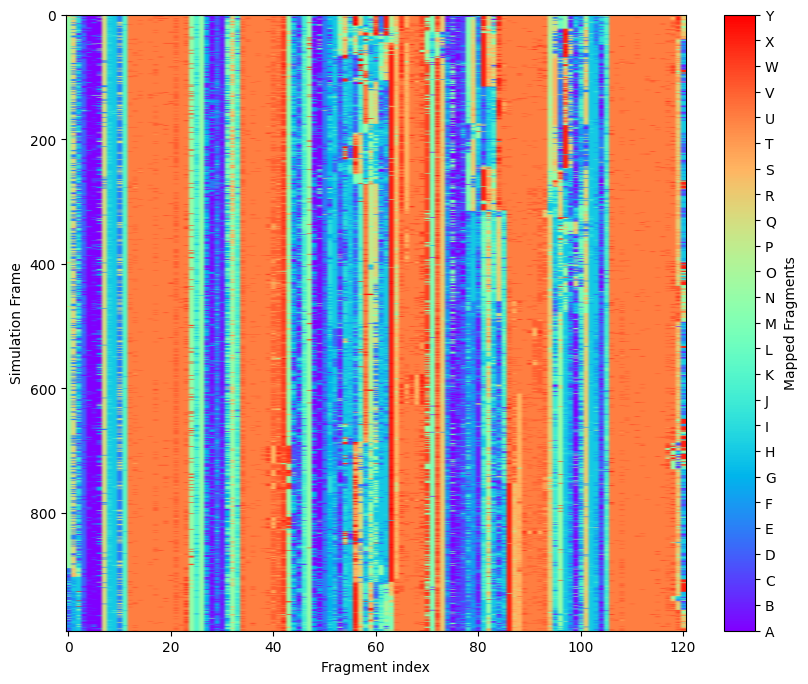

In [4]:
# Plot the randomized trajectory of the Structural Alphabet trajectory of NtrC active repl1
Allohub_plots.plot_SA_traj(sa_ntrc_active_100_1_norand.get_int_traj(), SAtraj.ALPHABETS["M32K25"], action="show")

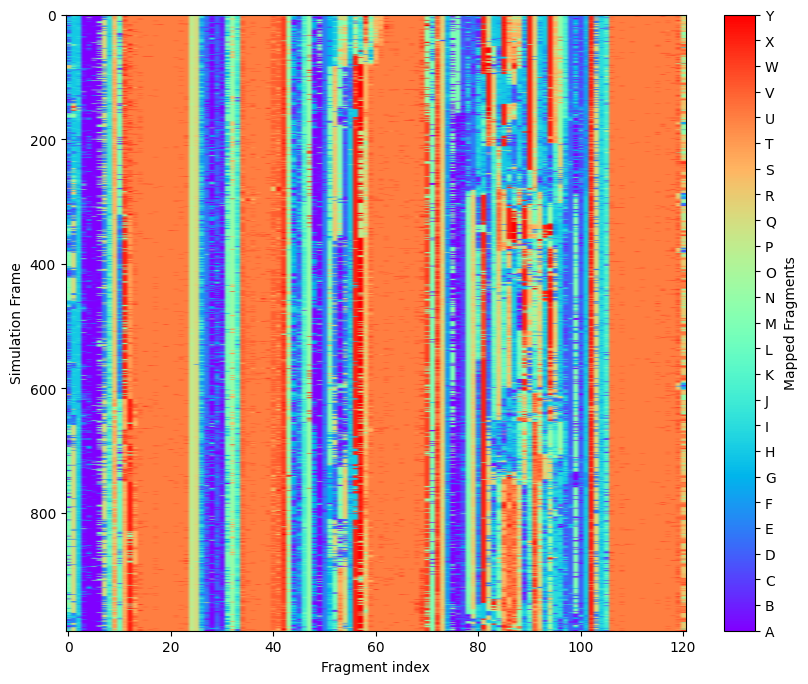

In [5]:
# Plot the randomized trajectory of the Structural Alphabet  trajectory of NtrC inactive repl1
Allohub_plots.plot_SA_traj(sa_ntrc_inactive_100_1_norand.get_int_traj(), SAtraj.ALPHABETS["M32K25"], action="show")

## Mutual information analysis

Now we will proceed to compute the mutual information for each block.
Trajectories with block 100 contain 9 blocks of 100 ns each.
Trajectories with block size 50 contain 19 blocks of 50 ns each.
Trajectories with block size 10 contains 99 blocks of 10 ns each.

In [6]:
print("Calculate the MI information")
# One can specify the number of workers to parallelize the process. max_workers=None would use all available resources.

mi_ntrc_inactive_100_1_norand = sa_ntrc_inactive_100_1_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 100, repl 1 finished")
mi_ntrc_inactive_100_2_norand = sa_ntrc_inactive_100_2_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 100, repl 2 finished")
mi_ntrc_inactive_100_3_norand = sa_ntrc_inactive_100_3_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 100, repl 3 finished")

mi_ntrc_inactive_50_1_norand = sa_ntrc_inactive_50_1_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 50, repl 1 finished")
mi_ntrc_inactive_50_2_norand = sa_ntrc_inactive_50_2_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 50, repl 2 finished")
mi_ntrc_inactive_50_3_norand = sa_ntrc_inactive_50_3_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 50, repl 3 finished")

mi_ntrc_inactive_10_1_norand = sa_ntrc_inactive_10_1_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 10, repl 1 finished")
mi_ntrc_inactive_10_2_norand = sa_ntrc_inactive_10_2_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 10, repl 2 finished")
mi_ntrc_inactive_10_3_norand = sa_ntrc_inactive_10_3_norand.compute_mis(max_workers=7)
print("NtrC inactive, no randomization, block size 10, repl 3 finished")

mi_ntrc_active_100_1_norand = sa_ntrc_active_100_1_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 100, repl 1 finished")
mi_ntrc_active_100_2_norand = sa_ntrc_active_100_2_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 100, repl 2 finished")
mi_ntrc_active_100_3_norand = sa_ntrc_active_100_3_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 100, repl 3 finished")

mi_ntrc_active_50_1_norand = sa_ntrc_active_50_1_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 50, repl 1 finished")
mi_ntrc_active_50_2_norand = sa_ntrc_active_50_2_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 50, repl 2 finished")
mi_ntrc_active_50_3_norand = sa_ntrc_active_50_3_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 50, repl 3 finished")

mi_ntrc_active_10_1_norand = sa_ntrc_active_10_1_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 10, repl 1 finished")
mi_ntrc_active_10_2_norand = sa_ntrc_active_10_2_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 10, repl 2 finished")
mi_ntrc_active_10_3_norand = sa_ntrc_active_10_3_norand.compute_mis(max_workers=7)
print("NtrC active, no randomization, block size 10, repl 3 finished")

mi_ntrc_inactive_100_1 = sa_ntrc_inactive_100_1.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 100, repl 1 finished")
mi_ntrc_inactive_100_2 = sa_ntrc_inactive_100_2.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 100, repl 2 finished")
mi_ntrc_inactive_100_3 = sa_ntrc_inactive_100_3.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 100, repl 3 finished")

mi_ntrc_inactive_50_1 = sa_ntrc_inactive_50_1.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 50, repl 1 finished")
mi_ntrc_inactive_50_2 = sa_ntrc_inactive_50_2.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 50, repl 2 finished")
mi_ntrc_inactive_50_3 = sa_ntrc_inactive_50_3.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 50, repl 3 finished")

mi_ntrc_inactive_10_1 = sa_ntrc_inactive_10_1.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 10, repl 1 finished")
mi_ntrc_inactive_10_2 = sa_ntrc_inactive_10_2.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 10, repl 2 finished")
mi_ntrc_inactive_10_3 = sa_ntrc_inactive_10_3.compute_mis(max_workers=7)
print("NtrC inactive, randomization, block size 10, repl 3 finished")

mi_ntrc_active_100_1 = sa_ntrc_active_100_1.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 100, repl 1 finished")
mi_ntrc_active_100_2 = sa_ntrc_active_100_2.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 100, repl 2 finished")
mi_ntrc_active_100_3 = sa_ntrc_active_100_3.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 100, repl 3 finished")

mi_ntrc_active_50_1 = sa_ntrc_active_50_1.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 50, repl 1 finished")
mi_ntrc_active_50_2 = sa_ntrc_active_50_2.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 50, repl 2 finished")
mi_ntrc_active_50_3 = sa_ntrc_active_50_3.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 50, repl 3 finished")

mi_ntrc_active_10_1 = sa_ntrc_active_10_1.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 10, repl 1 finished")
mi_ntrc_active_10_2 = sa_ntrc_active_10_2.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 10, repl 2 finished")
mi_ntrc_active_10_3 = sa_ntrc_active_10_3.compute_mis(max_workers=7)
print("NtrC active, randomization, block size 10, repl 3 finished")

Calculate the MI information
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:18<00:00,  2.01s/block]


TRAJECTORY COMPLETED
NtrC inactive, no randomization, block size 100, repl 1 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:15<00:00,  1.75s/block]


TRAJECTORY COMPLETED
NtrC inactive, no randomization, block size 100, repl 2 finished
ENCODING TRAJECTORY


...

TRAJECTORY COMPLETED
NtrC active, randomization, block size 10, repl 1 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 99/99 [01:19<00:00,  1.24block/s]


TRAJECTORY COMPLETED
NtrC active, randomization, block size 10, repl 2 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 99/99 [01:13<00:00,  1.35block/s]

TRAJECTORY COMPLETED
NtrC active, randomization, block size 10, repl 3 finished


## Eigenvector decomposition

The eigenvector decomposition of the obtained MI matrices can be used to asses convergence.
The main motions of well converged simulations should have relatively high eigenvector overlap (>0.3).

Overlap between replicates can be used as a way to asses relaiability of the results. (Higher convergences = Higher confidences)

In [7]:
# Do an eigenvector decomposition of the matrices
from tqdm import tqdm

print("Do an eigenvector decomposition of the matrices")

for mi_tr in tqdm(mi_ntrc_inactive_100_1_norand, desc="Eigenvector decomposition for Ntrc 100 norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_2_norand, desc="Eigenvector decomposition for Ntrc 100 norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_3_norand, desc="Eigenvector decomposition for Ntrc 100 norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_inactive_50_1_norand, desc="Eigenvector decomposition for Ntrc 50 norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_50_2_norand, desc="Eigenvector decomposition for Ntrc 50 norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_50_3_norand, desc="Eigenvector decomposition for Ntrc 50 norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_inactive_10_1_norand, desc="Eigenvector decomposition for Ntrc 10 norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_10_2_norand, desc="Eigenvector decomposition for Ntrc 10 norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_10_3_norand, desc="Eigenvector decomposition for Ntrc 10 norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()
    
for mi_tr in tqdm(mi_ntrc_inactive_100_1, desc="Eigenvector decomposition for Ntrc 100 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_2, desc="Eigenvector decomposition for Ntrc 100 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_3, desc="Eigenvector decomposition for Ntrc 100 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_inactive_50_1, desc="Eigenvector decomposition for Ntrc 50 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_50_2, desc="Eigenvector decomposition for Ntrc 50 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_50_3, desc="Eigenvector decomposition for Ntrc 50 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_inactive_10_1, desc="Eigenvector decomposition for Ntrc 10 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_10_2, desc="Eigenvector decomposition for Ntrc 10 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_10_3, desc="Eigenvector decomposition for Ntrc 10 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_active_100_1_norand, desc="Eigenvector decomposition for Ntrc 100 act norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_2_norand, desc="Eigenvector decomposition for Ntrc 100 act norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_3_norand, desc="Eigenvector decomposition for Ntrc 100 act norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_active_50_1_norand, desc="Eigenvector decomposition for Ntrc 50 act norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_50_2_norand, desc="Eigenvector decomposition for Ntrc 50 act norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_50_3_norand, desc="Eigenvector decomposition for Ntrc 50 act norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_active_10_1_norand, desc="Eigenvector decomposition for Ntrc 10 act norand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_10_2_norand, desc="Eigenvector decomposition for Ntrc 10 act norand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_10_3_norand, desc="Eigenvector decomposition for Ntrc act 10 norand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()
    
for mi_tr in tqdm(mi_ntrc_active_100_1, desc="Eigenvector decomposition for Ntrc act 100 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_2, desc="Eigenvector decomposition for Ntrc act 100 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_3, desc="Eigenvector decomposition for Ntrc act 100 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_active_50_1, desc="Eigenvector decomposition for Ntrc act 50 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_50_2, desc="Eigenvector decomposition for Ntrc act 50 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_50_3, desc="Eigenvector decomposition for Ntrc act 50 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_active_10_1, desc="Eigenvector decomposition for Ntrc act 10 rand rep1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_10_2, desc="Eigenvector decomposition for Ntrc act 10 rand rep2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_10_3, desc="Eigenvector decomposition for Ntrc act 10 rand rep3", unit="matrix"):
    mi_tr.compute_eigensystem()

Do an eigenvector decomposition of the matrices


Eigenvector decomposition for Ntrc 100 norand rep1: 100%|██████████| 9/9 [00:00<00:00, 16.86matrix/s]
Eigenvector decomposition for Ntrc 100 norand rep2: 100%|██████████| 9/9 [00:00<00:00, 22.02matrix/s]
Eigenvector decomposition for Ntrc 100 norand rep3: 100%|██████████| 9/9 [00:00<00:00, 31.60matrix/s]
Eigenvector decomposition for Ntrc 50 norand rep1: 100%|██████████| 19/19 [00:00<00:00, 99.04matrix/s]
Eigenvector decomposition for Ntrc 50 norand rep2: 100%|██████████| 19/19 [00:00<00:00, 86.30matrix/s]
Eigenvector decomposition for Ntrc 50 norand rep3: 100%|██████████| 19/19 [00:00<00:00, 77.04matrix/s]
Eigenvector decomposition for Ntrc 10 norand rep1: 100%|██████████| 99/99 [00:01<00:00, 90.13matrix/s]
Eigenvector decomposition for Ntrc 10 norand rep2: 100%|██████████| 99/99 [00:01<00:00, 93.30matrix/s]
Eigenvector decomposition for Ntrc 10 norand rep3: 100%|██████████| 99/99 [00:01<00:00, 91.38matrix/s]
Eigenvector decomposition for Ntrc 10 rand rep3: 100%|██████████| 99/99 [00:

## Convergence analysis

Overlap can be now computed using the Overlap object.

In this analysis we are using the top 3 eigenvectors which should explain most of the observed variability.

In [8]:
# Create the overlap handler to compute similarities between the trajectories

# Random 100
overlap_100 = Overlap.Overlap([mi_ntrc_inactive_100_1, mi_ntrc_inactive_100_2, mi_ntrc_inactive_100_3,
                            mi_ntrc_active_100_1,  mi_ntrc_active_100_2, mi_ntrc_active_100_3], ev_list=[0,1,2])
overlap_100.fill_overlap_matrix()

# No Random 100
overlap_100_norand = Overlap.Overlap([mi_ntrc_inactive_100_1_norand, mi_ntrc_inactive_100_2_norand, mi_ntrc_inactive_100_3_norand,
                            mi_ntrc_active_100_1_norand,  mi_ntrc_active_100_2_norand, mi_ntrc_active_100_3_norand], ev_list=[0,1,2])
overlap_100_norand.fill_overlap_matrix()

# Random 50
overlap_50 = Overlap.Overlap([mi_ntrc_inactive_50_1, mi_ntrc_inactive_50_2, mi_ntrc_inactive_50_3,
                            mi_ntrc_active_50_1,  mi_ntrc_active_50_2, mi_ntrc_active_50_3], ev_list=[0,1,2])
overlap_50.fill_overlap_matrix()

# No Random 50
overlap_50_norand = Overlap.Overlap([mi_ntrc_inactive_50_1_norand, mi_ntrc_inactive_50_2_norand, mi_ntrc_inactive_50_3_norand,
                            mi_ntrc_active_50_1_norand,  mi_ntrc_active_50_2_norand, mi_ntrc_active_50_3_norand], ev_list=[0,1,2])
overlap_50_norand.fill_overlap_matrix()

# Random 10
overlap_10 = Overlap.Overlap([mi_ntrc_inactive_10_1, mi_ntrc_inactive_10_2, mi_ntrc_inactive_10_3,
                            mi_ntrc_active_10_1,  mi_ntrc_active_10_2, mi_ntrc_active_10_3], ev_list=[0,1,2])
overlap_10.fill_overlap_matrix()

# No Random 10
overlap_10_norand = Overlap.Overlap([mi_ntrc_inactive_10_1_norand, mi_ntrc_inactive_10_2_norand, mi_ntrc_inactive_10_3_norand,
                            mi_ntrc_active_10_1_norand,  mi_ntrc_active_10_2_norand, mi_ntrc_active_10_3_norand], ev_list=[0,1,2])
overlap_10_norand.fill_overlap_matrix()

The results can now be plotted to examine the convergence

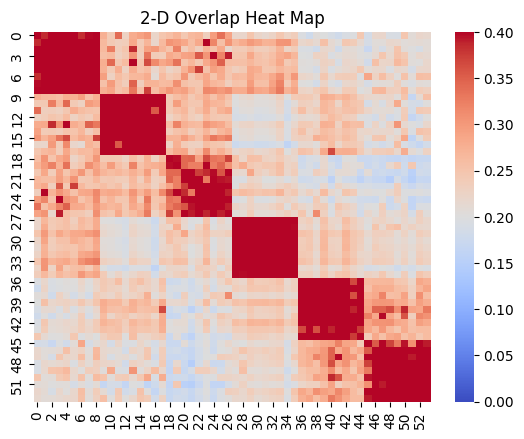

In [9]:
# Overlap for block 100 randomized
Allohub_plots.plot_overlap(overlap_100.get_overlap_matrix(), vmax=0.4, action="show")

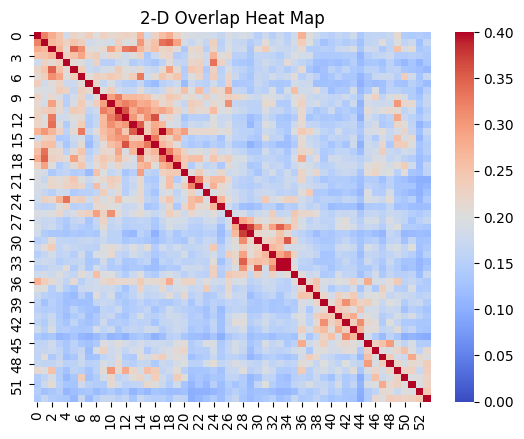

In [10]:
# Overlap for block 100 no randomized
Allohub_plots.plot_overlap(overlap_100_norand.get_overlap_matrix(), vmax=0.4, action="show")

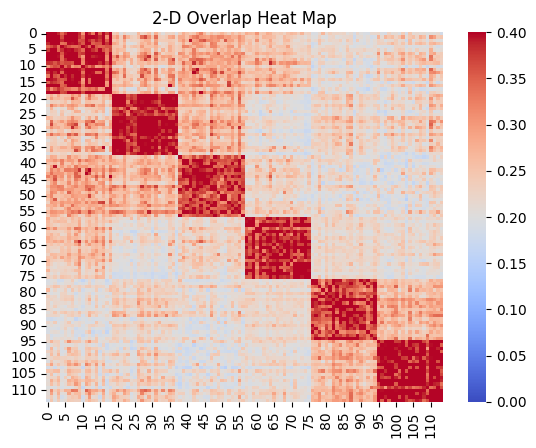

In [11]:
# Overlap for block 50 randomized
Allohub_plots.plot_overlap(overlap_50.get_overlap_matrix(), vmax=0.4, action="show")

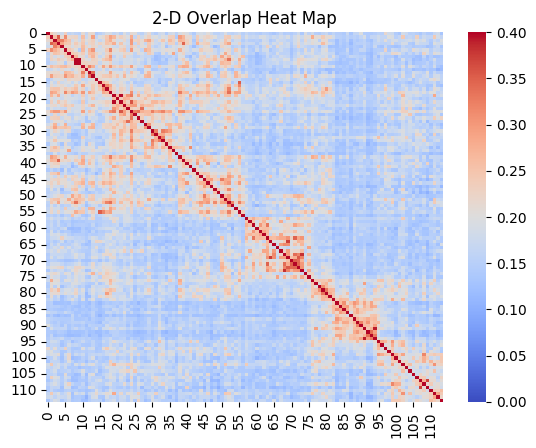

In [12]:
# Overlap for block 50 no randomized
Allohub_plots.plot_overlap(overlap_50_norand.get_overlap_matrix(), vmax=0.4, action="show")

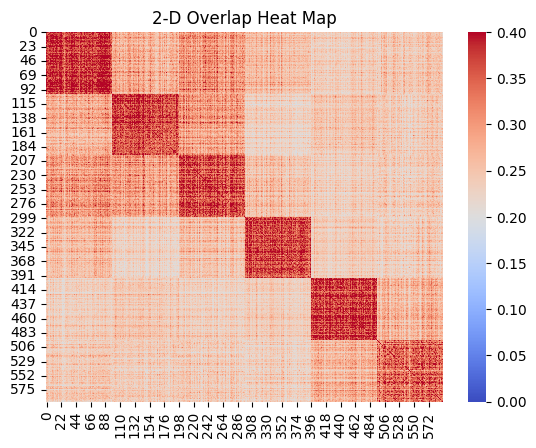

In [13]:
# Overlap for block 10 randomized
Allohub_plots.plot_overlap(overlap_10.get_overlap_matrix(), vmax=0.4, action="show")

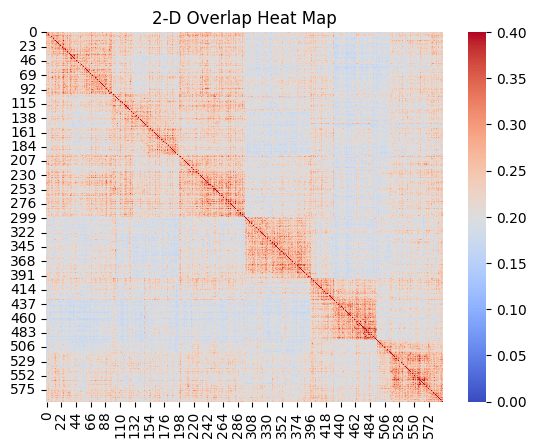

In [14]:
# Overlap for block 10 no randomized
Allohub_plots.plot_overlap(overlap_10_norand.get_overlap_matrix(), vmax=0.4, action="show")

In [15]:
# Compute similarities for the 100 block size encodings
similarity_matrix_100_norand = overlap_100_norand.compute_similarities()
similarity_matrix_100 = overlap_100.compute_similarities()
similarity_matrix_50_norand = overlap_50_norand.compute_similarities()
similarity_matrix_50 = overlap_50.compute_similarities()
similarity_matrix_10_norand = overlap_10_norand.compute_similarities()
similarity_matrix_10 = overlap_10.compute_similarities()

SIMILARITIES BETWEEN TRAJECTORY 0  and 1
	Overlap between trajectories: 0.2059
	Overlap of trajectory 1 with itself: 0.3168
	Overlap of trajectory 2 with itself: 0.363
 Similary 0.866
SIMILARITIES BETWEEN TRAJECTORY 0  and 2
	Overlap between trajectories: 0.2021
	Overlap of trajectory 1 with itself: 0.3168
	Overlap of trajectory 2 with itself: 0.3039
 Similary 0.8918
SIMILARITIES BETWEEN TRAJECTORY 0  and 3
	Overlap between trajectories: 0.1652
	Overlap of trajectory 1 with itself: 0.3168
	Overlap of trajectory 2 with itself: 0.3337
 Similary 0.84
SIMILARITIES BETWEEN TRAJECTORY 0  and 4
	Overlap between trajectories: 0.1512
	Overlap of trajectory 1 with itself: 0.3168
	Overlap of trajectory 2 with itself: 0.3048
 Similary 0.8404
SIMILARITIES BETWEEN TRAJECTORY 0  and 5
	Overlap between trajectories: 0.1524
	Overlap of trajectory 1 with itself: 0.3168
	Overlap of trajectory 2 with itself: 0.2978
 Similary 0.8451
SIMILARITIES BETWEEN TRAJECTORY 1  and 2
	Overlap between trajectories: 0.

In [16]:
# Statistic significance of convergence for block 100
# The groups are simulation 0,1,2 inactive 3,4,5 active

# No randomization group
within_conditions = [similarity_matrix_100_norand[0][1], similarity_matrix_100_norand[0][2], similarity_matrix_100_norand[1][2], 
                     similarity_matrix_100_norand[3][4], similarity_matrix_100_norand[3][5], similarity_matrix_100_norand[4][5]]

between_conditions = [similarity_matrix_100_norand[0][3], similarity_matrix_100_norand[0][4], similarity_matrix_100_norand[0][5], 
                      similarity_matrix_100_norand[1][3], similarity_matrix_100_norand[1][4], similarity_matrix_100_norand[1][5],
                      similarity_matrix_100_norand[2][3], similarity_matrix_100_norand[2][4], similarity_matrix_100_norand[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 100 is {p_value}")

within_conditions = [similarity_matrix_50_norand[0][1], similarity_matrix_50_norand[0][2], similarity_matrix_50_norand[1][2], 
                     similarity_matrix_50_norand[3][4], similarity_matrix_50_norand[3][5], similarity_matrix_50_norand[4][5]]

between_conditions = [similarity_matrix_50_norand[0][3], similarity_matrix_50_norand[0][4], similarity_matrix_50_norand[0][5], 
                      similarity_matrix_50_norand[1][3], similarity_matrix_50_norand[1][4], similarity_matrix_50_norand[1][5],
                      similarity_matrix_50_norand[2][3], similarity_matrix_50_norand[2][4], similarity_matrix_50_norand[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 50 is {p_value}")

within_conditions = [similarity_matrix_10_norand[0][1], similarity_matrix_10_norand[0][2], similarity_matrix_10_norand[1][2], 
                     similarity_matrix_10_norand[3][4], similarity_matrix_10_norand[3][5], similarity_matrix_10_norand[4][5]]

between_conditions = [similarity_matrix_10_norand[0][3], similarity_matrix_10_norand[0][4], similarity_matrix_10_norand[0][5], 
                      similarity_matrix_10_norand[1][3], similarity_matrix_10_norand[1][4], similarity_matrix_10_norand[1][5],
                      similarity_matrix_10_norand[2][3], similarity_matrix_10_norand[2][4], similarity_matrix_10_norand[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 10 is {p_value}")


# Randomization group
within_conditions = [similarity_matrix_100[0][1], similarity_matrix_100[0][2], similarity_matrix_100[1][2], 
                     similarity_matrix_100[3][4], similarity_matrix_100[3][5], similarity_matrix_100[4][5]]

between_conditions = [similarity_matrix_100[0][3], similarity_matrix_100[0][4], similarity_matrix_100[0][5], 
                      similarity_matrix_100[1][3], similarity_matrix_100[1][4], similarity_matrix_100[1][5],
                      similarity_matrix_100[2][3], similarity_matrix_100[2][4], similarity_matrix_100[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the randomized encoded trajectory with block 100 is {p_value}")

within_conditions = [similarity_matrix_50[0][1], similarity_matrix_50[0][2], similarity_matrix_50[1][2], 
                     similarity_matrix_50[3][4], similarity_matrix_50[3][5], similarity_matrix_50[4][5]]

between_conditions = [similarity_matrix_50[0][3], similarity_matrix_50[0][4], similarity_matrix_50[0][5], 
                      similarity_matrix_50[1][3], similarity_matrix_50[1][4], similarity_matrix_50[1][5],
                      similarity_matrix_50[2][3], similarity_matrix_50[2][4], similarity_matrix_50[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the randomized encoded trajectory with block 50 is {p_value}")

within_conditions = [similarity_matrix_10[0][1], similarity_matrix_10[0][2], similarity_matrix_10[1][2], 
                     similarity_matrix_10[3][4], similarity_matrix_10[3][5], similarity_matrix_10[4][5]]

between_conditions = [similarity_matrix_10[0][3], similarity_matrix_10[0][4], similarity_matrix_10[0][5], 
                      similarity_matrix_10[1][3], similarity_matrix_10[1][4], similarity_matrix_10[1][5],
                      similarity_matrix_10[2][3], similarity_matrix_10[2][4], similarity_matrix_10[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for the randomized encoded trajectory with block 10 is {p_value}")

p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 100 is 0.06421072830581312
p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 50 is 0.10359030100348482
p-value of convergence within vs between conditions for the non randomization encoded trajectory with block 10 is 0.05838242998217478
p-value of convergence within vs between conditions for the randomized encoded trajectory with block 100 is 0.007290212688868098
p-value of convergence within vs between conditions for the randomized encoded trajectory with block 50 is 0.02637500321221996
p-value of convergence within vs between conditions for the randomized encoded trajectory with block 10 is 0.02990015973094961


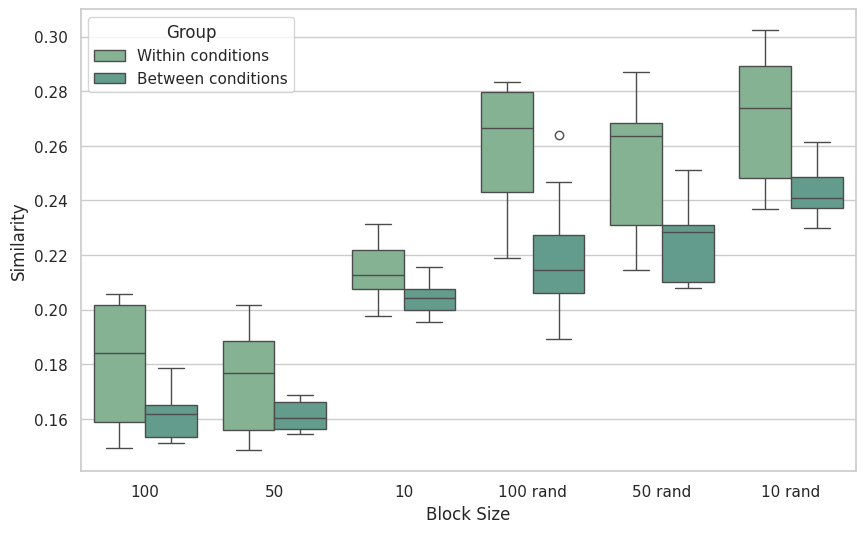

In [17]:
# Create a box plot for the different block size
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# df to hold data
data = {
    "Block Size": [],
    "Group": [],
    "Similarity": []
}

# group that each index belongs to.
group = [0,0,0,1,1,1]

# Mapping of names to similarity matrices
sim_map = {"100": similarity_matrix_100_norand, "50": similarity_matrix_50_norand, "10": similarity_matrix_10_norand,
           "100 rand": similarity_matrix_100, "50 rand": similarity_matrix_50, "10 rand": similarity_matrix_10}

# Format the data into a dict for seaborn
for key in sim_map:
    matrix_to_use = sim_map[key]
    for i in range(6): # 6 simulations
        for j in range(i,6):
            g1 = group[i]
            g2 = group[j]
            if i == j:
                continue
            elif g1 == g2:
                data["Block Size"].append(key)
                data["Group"].append("Within conditions")
                data["Similarity"].append(matrix_to_use[i][j])
            else:
                data["Block Size"].append(key)
                data["Group"].append("Between conditions")
                data["Similarity"].append(matrix_to_use[i][j])

# Convert data to DataFrame
df = pd.DataFrame(data)

# Set Seaborn style
sns.set_theme(style="whitegrid", palette="crest")

# Create the boxplot
plt.figure(figsize=(10, 6))
sns.boxplot( data=df, x="Block Size", y="Similarity", hue="Group")

# Add labels
plt.xlabel("Block Size", fontsize=12)
plt.ylabel("Similarity", fontsize=12)
plt.legend(title="Group")

# Show the plot
plt.show()

The similarity (convergence) for the non randomized at block size 10 is barely significative p-value ~ 0.05 while the randomization of blocks greatly helped the convergence of the signal with p-values < 0.05 for all block sizes.

## Up and down regulated fragments detection

Finally, we will compare the top hits for the different encoding sizes with randomization and without.

In [18]:
# Find upregulated and downregulated fragments
print("Find upregulated and downregulated fragments for randomized 100")

# 100 block random
updown_regulated_fragments = overlap_100.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
# The obtained dictionary has as keys the pairs of conditions. In this case (0,1).
# If more conditions were used one would have all the additional pairing (0,1), (0,2), (1,2) ....
t12_updown_100 = updown_regulated_fragments[(0,1)]

# 100 block no random
updown_regulated_fragments = overlap_100_norand.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
t12_updown_100_norand = updown_regulated_fragments[(0,1)]

# 50 block random
updown_regulated_fragments = overlap_50.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
t12_updown_50 = updown_regulated_fragments[(0,1)]

# 50 block no random
updown_regulated_fragments = overlap_50_norand.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
t12_updown_50_norand = updown_regulated_fragments[(0,1)]

# 10 block random
updown_regulated_fragments = overlap_10.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
t12_updown_10 = updown_regulated_fragments[(0,1)]

# 10 block no random
updown_regulated_fragments = overlap_10_norand.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)
t12_updown_10_norand = updown_regulated_fragments[(0,1)]

Find upregulated and downregulated fragments for randomized 100
     FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
0           (0, 1)       -0.123072  0.447505  0.203693  0.221832   
1           (0, 2)       -0.892619  0.000013  0.099332  0.184413   
2           (0, 3)       -0.184633  0.177322  0.069483  0.078970   
3           (0, 4)       -0.329466  0.059657  0.053082  0.066700   
4           (0, 5)       -0.466802  0.039576  0.043965  0.060762   
...            ...             ...       ...       ...       ...   
7255    (117, 119)        0.373160  0.304201  0.062857  0.048531   
7256    (117, 120)        0.312794  0.305761  0.051024  0.041078   
7257    (118, 119)        1.172576  0.025107  0.189950  0.084267   
7258    (118, 120)        1.031750  0.027216  0.115946  0.056711   
7259    (119, 120)       -0.338872  0.035184  0.178182  0.225359   

      AdjustedPValues  
0            0.564435  
1            0.000086  
2            0.284247  
3            0.120109  

Now we can filter the fragment pairs based on their p value and fold change

In [19]:
# Filtering parameters
pval_threshold = 0.01
fold_change_threshold = 2

# First extract significant fragments
significant_fragments_100 = t12_updown_100[t12_updown_100['AdjustedPValues'] < pval_threshold]
significant_fragments_100_norand = t12_updown_100_norand[t12_updown_100_norand['AdjustedPValues'] < pval_threshold]
significant_fragments_50 = t12_updown_50[t12_updown_50['AdjustedPValues'] < pval_threshold]
significant_fragments_50_norand = t12_updown_50_norand[t12_updown_50_norand['AdjustedPValues'] < pval_threshold]
significant_fragments_10 = t12_updown_10[t12_updown_10['AdjustedPValues'] < pval_threshold]
significant_fragments_10_norand = t12_updown_10_norand[t12_updown_10_norand['AdjustedPValues'] < pval_threshold]

In [20]:
# Second, filter by fold change and print top 5
# 100 random
up_reg_100 = significant_fragments_100[significant_fragments_100['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_100.head(5))

# 50 random
up_reg_50 = significant_fragments_50[significant_fragments_50['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_50.head(5))

# 10 random
up_reg_10 = significant_fragments_10[significant_fragments_10['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_10.head(5))

     FragmentPairs  log2FoldChange       PValues   MIfrag1   MIfrag2  \
1776      (15, 97)        8.532368  1.185237e-09  0.018100  0.000049   
2865      (26, 97)        6.128607  3.101384e-18  0.067268  0.000961   
1131       (9, 97)        4.491642  5.392162e-12  0.098169  0.004364   
6801      (90, 97)        4.491203  4.398142e-11  0.198793  0.008839   
1020       (8, 97)        3.955166  3.650898e-08  0.100521  0.006481   

      AdjustedPValues  
1776     2.167462e-08  
2865     8.595436e-16  
1131     1.747638e-10  
6801     1.178248e-09  
1020     4.699560e-07  
     FragmentPairs  log2FoldChange       PValues   MIfrag1   MIfrag2  \
2865      (26, 97)        7.232461  1.857302e-35  0.112926  0.000751   
6692     (86, 114)        5.821541  9.191986e-05  0.246535  0.004359   
1892     (16, 109)        5.587254  5.207565e-05  0.263353  0.005478   
7187    (108, 114)        4.987989  3.756430e-03  0.144818  0.004563   
1131       (9, 97)        4.958864  3.263259e-25  0.145251  0.0

With the randomization approach the three block sizes achieved similar upregulated fragments

In [21]:
# Second, filter by fold change and print top 5
# 100 random
up_reg_100_norand = significant_fragments_100_norand[significant_fragments_100_norand['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_100.head(5))

# 50 random
up_reg_50_norand = significant_fragments_50_norand[significant_fragments_50_norand['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_50.head(5))

# 10 random
up_reg_10_norand = significant_fragments_10_norand[significant_fragments_10_norand['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
print(up_reg_10.head(5))

     FragmentPairs  log2FoldChange       PValues   MIfrag1   MIfrag2  \
1776      (15, 97)        8.532368  1.185237e-09  0.018100  0.000049   
2865      (26, 97)        6.128607  3.101384e-18  0.067268  0.000961   
1131       (9, 97)        4.491642  5.392162e-12  0.098169  0.004364   
6801      (90, 97)        4.491203  4.398142e-11  0.198793  0.008839   
1020       (8, 97)        3.955166  3.650898e-08  0.100521  0.006481   

      AdjustedPValues  
1776     2.167462e-08  
2865     8.595436e-16  
1131     1.747638e-10  
6801     1.178248e-09  
1020     4.699560e-07  
     FragmentPairs  log2FoldChange       PValues   MIfrag1   MIfrag2  \
2865      (26, 97)        7.232461  1.857302e-35  0.112926  0.000751   
6692     (86, 114)        5.821541  9.191986e-05  0.246535  0.004359   
1892     (16, 109)        5.587254  5.207565e-05  0.263353  0.005478   
7187    (108, 114)        4.987989  3.756430e-03  0.144818  0.004563   
1131       (9, 97)        4.958864  3.263259e-25  0.145251  0.0

In [22]:
# Function to obtain most frequent fragments 
def get_top_fragments(df_reg):
    top_fragments_count = {}

    for fragment_pair in df_reg["FragmentPairs"]:
        top_fragments_count.setdefault(fragment_pair[0], 0) # record first fragment of the pair
        top_fragments_count.setdefault(fragment_pair[1], 0) # record second fragment of the pair
        top_fragments_count[fragment_pair[0]] += 1
        top_fragments_count[fragment_pair[1]] += 1

    # sort based on counts
    top_fragments_count = dict(sorted(top_fragments_count.items(), key=lambda item: item[1], reverse=True))

    return top_fragments_count

# Block 100 randomized

top_fragments_count = get_top_fragments(up_reg_100)
# Print top 5 most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 100 block size randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

# Block 50 randomized

top_fragments_count = get_top_fragments(up_reg_50)
# Print top 5 most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 50 block size randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

# Block 10 randomized

top_fragments_count = get_top_fragments(up_reg_10)
# Print top 5most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 10 block size randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

NtrC 100 block size randomized
Fragment 89 appears 58 times.
Fragment 90 appears 55 times.
Fragment 91 appears 55 times.
Fragment 97 appears 39 times.
Fragment 92 appears 31 times.
NtrC 50 block size randomized
Fragment 91 appears 70 times.
Fragment 89 appears 56 times.
Fragment 90 appears 47 times.
Fragment 97 appears 36 times.
Fragment 92 appears 29 times.
NtrC 10 block size randomized
Fragment 91 appears 48 times.
Fragment 89 appears 36 times.
Fragment 92 appears 26 times.
Fragment 90 appears 25 times.
Fragment 65 appears 22 times.


All block sizes yielded a similar results with the same key fragments appearing on the top hits

In [23]:
# Block 100 non randomized

top_fragments_count = get_top_fragments(up_reg_100_norand)
# Print top 5 most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 100 block size non randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

# Block 50 non randomized

top_fragments_count = get_top_fragments(up_reg_50_norand)
# Print top 5 most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 50 block size non randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

# Block 10 non randomized

top_fragments_count = get_top_fragments(up_reg_10_norand)
# Print top 5 most appearing fragments
dict_keys = list(top_fragments_count.keys())
print("NtrC 10 block size non randomized")
for i in range(5):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")

NtrC 100 block size non randomized
Fragment 97 appears 23 times.
Fragment 89 appears 19 times.
Fragment 91 appears 19 times.
Fragment 88 appears 13 times.
Fragment 90 appears 10 times.
NtrC 50 block size non randomized
Fragment 97 appears 18 times.
Fragment 91 appears 13 times.
Fragment 89 appears 7 times.
Fragment 95 appears 7 times.
Fragment 88 appears 6 times.
NtrC 10 block size non randomized
Fragment 60 appears 23 times.
Fragment 83 appears 22 times.
Fragment 84 appears 12 times.
Fragment 62 appears 11 times.
Fragment 54 appears 9 times.


Still a similar signal can be recovered for the top appearing fragments, given a long enough trajectory.

## Conclusions

In this section, we have examined how to directly encode MD trajectories into structural alphabets and observed the improvements on consistency and reproducibility added by the addition of randomized encoding blocks.

# Comparison of Alphabets

On this next section the structural alphabets of 3DI and M32k25 will be compared.

We will use a block size of 100 and randomized blocks for both alphabets.
This section will recompute the whole process with the exception of the step to convert the MD into structural alphabets, but those files are already precomputed in the data folder.
If the previous section has been already run, one can comment the lines for already precomputed objects.

In [24]:
# Initialize Structural Alphabet trajectory handler
print("Initialize Structural Alphabet trajectory handler")

# Set seeds for reproducibility
seed = 42  # Replace with any integer
import random
np.random.seed(seed)
random.seed(seed)

# With randomization
sa_ntrc_active_100_1 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_2 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_active_100_3 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_inactive_100_1 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_2 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])
sa_ntrc_inactive_100_3 = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["M32K25"])

sa_ntrc_active_100_1_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])
sa_ntrc_active_100_2_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])
sa_ntrc_active_100_3_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])

sa_ntrc_inactive_100_1_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])
sa_ntrc_inactive_100_2_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])
sa_ntrc_inactive_100_3_3di = SAtraj.SAtraj(block_size=100, alphabet=SAtraj.ALPHABETS["3DI"])

# Load data
sa_ntrc_active_100_1.load_data("data_NtrC/encoded_NtrC_active_repl1_mk.sa")
sa_ntrc_active_100_2.load_data("data_NtrC/encoded_NtrC_active_repl2_mk.sa")
sa_ntrc_active_100_3.load_data("data_NtrC/encoded_NtrC_active_repl3_mk.sa")

sa_ntrc_inactive_100_1.load_data("data_NtrC/encoded_NtrC_inactive_repl1_mk.sa")
sa_ntrc_inactive_100_2.load_data("data_NtrC/encoded_NtrC_inactive_repl2_mk.sa")
sa_ntrc_inactive_100_3.load_data("data_NtrC/encoded_NtrC_inactive_repl3_mk.sa")

sa_ntrc_active_100_1_3di.load_data("data_NtrC/encoded_NtrC_active_repl1_3di.sa")
sa_ntrc_active_100_2_3di.load_data("data_NtrC/encoded_NtrC_active_repl2_3di.sa")
sa_ntrc_active_100_3_3di.load_data("data_NtrC/encoded_NtrC_active_repl3_3di.sa")

sa_ntrc_inactive_100_1_3di.load_data("data_NtrC/encoded_NtrC_inactive_repl1_3di.sa")
sa_ntrc_inactive_100_2_3di.load_data("data_NtrC/encoded_NtrC_inactive_repl2_3di.sa")
sa_ntrc_inactive_100_3_3di.load_data("data_NtrC/encoded_NtrC_inactive_repl3_3di.sa")


Initialize Structural Alphabet trajectory handler


## Trajectory examination

One can examine the encoded structure string as well as all other analysis using the provided plotting functions.

Alternatively, one can addapt the provided plotting functions for other applications.
They are all locate din the file Allohub_plots.py

To display the plots the argument action = "show" should be used while for saving to a file it should be action="save"
If the save option is provided the name of the file can be specified with name="my_name.png".
The format of the image will depend on the format specified in the file name.

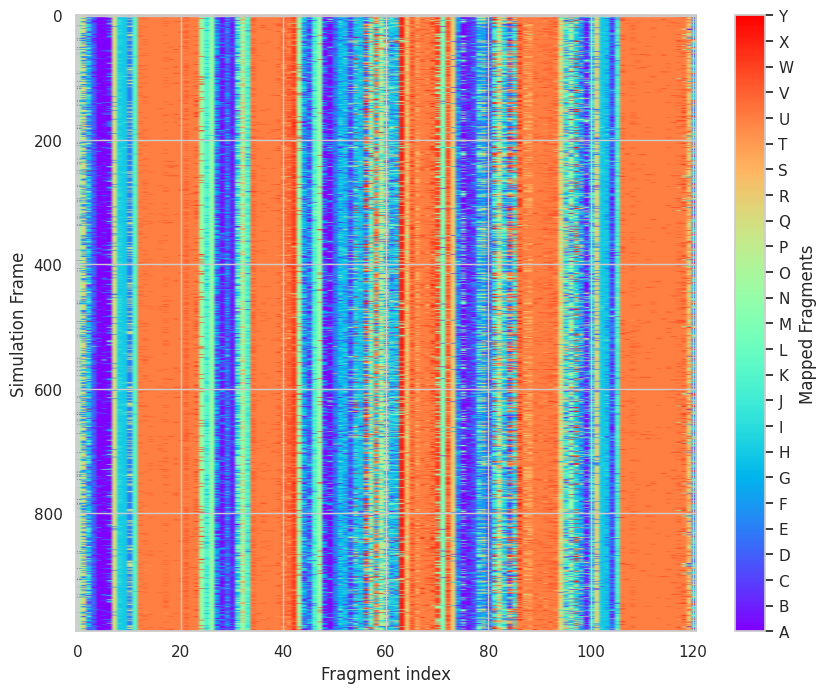

In [25]:
# Plot the randomized trajectory of the Structural Alphabet M32K25 of NtrC active repl1
Allohub_plots.plot_SA_traj(sa_ntrc_active_100_1.get_int_traj(), SAtraj.ALPHABETS["M32K25"], action="show")

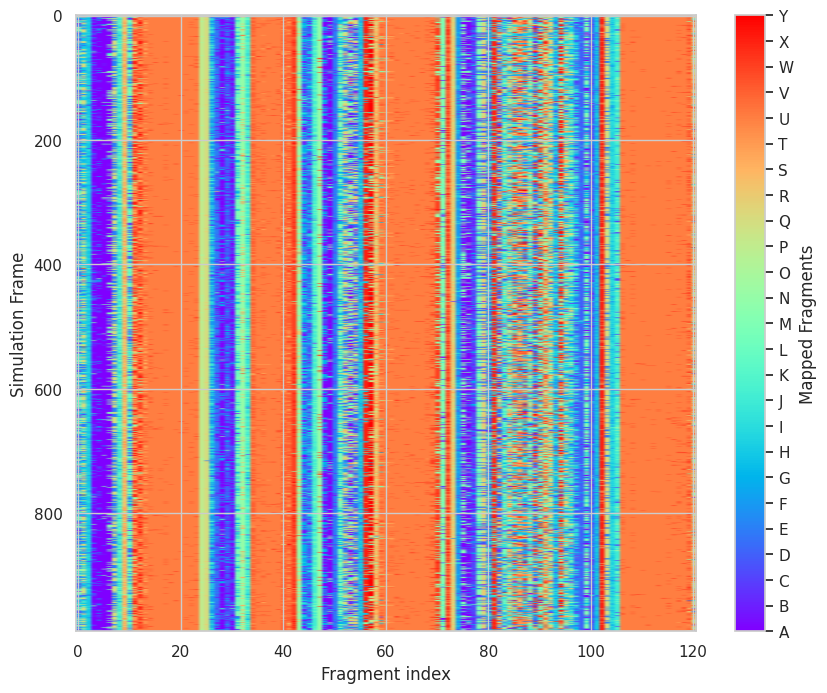

In [26]:
# Plot the randomized trajectory of the Structural Alphabet M32K25 of NtrC inactive repl1
Allohub_plots.plot_SA_traj(sa_ntrc_inactive_100_1.get_int_traj(), SAtraj.ALPHABETS["M32K25"], action="show")

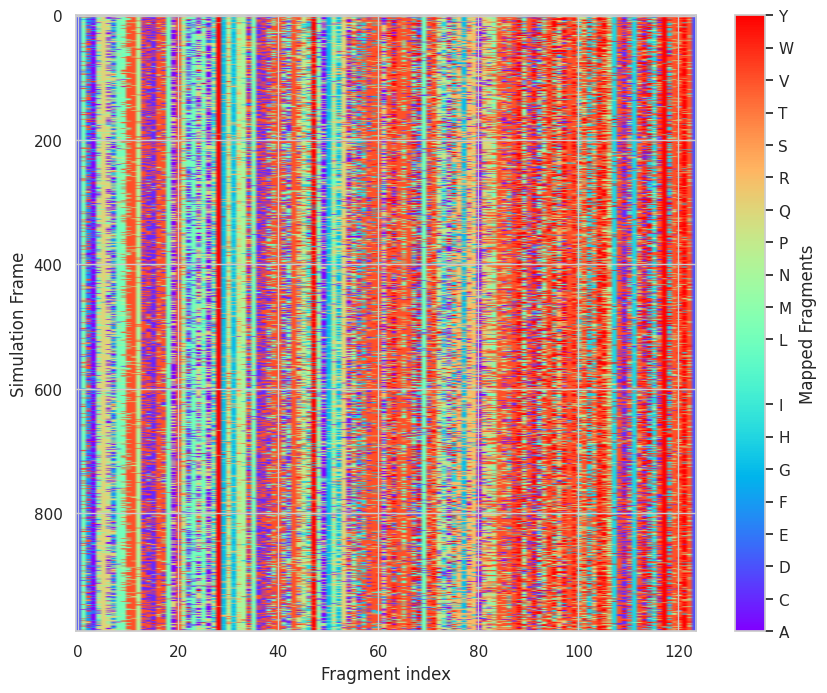

In [27]:
# Plot the randomized trajectory of the Structural Alphabet 3DI of NtrC active repl1
Allohub_plots.plot_SA_traj(sa_ntrc_active_100_1_3di.get_int_traj(), SAtraj.ALPHABETS["3DI"], action="show")

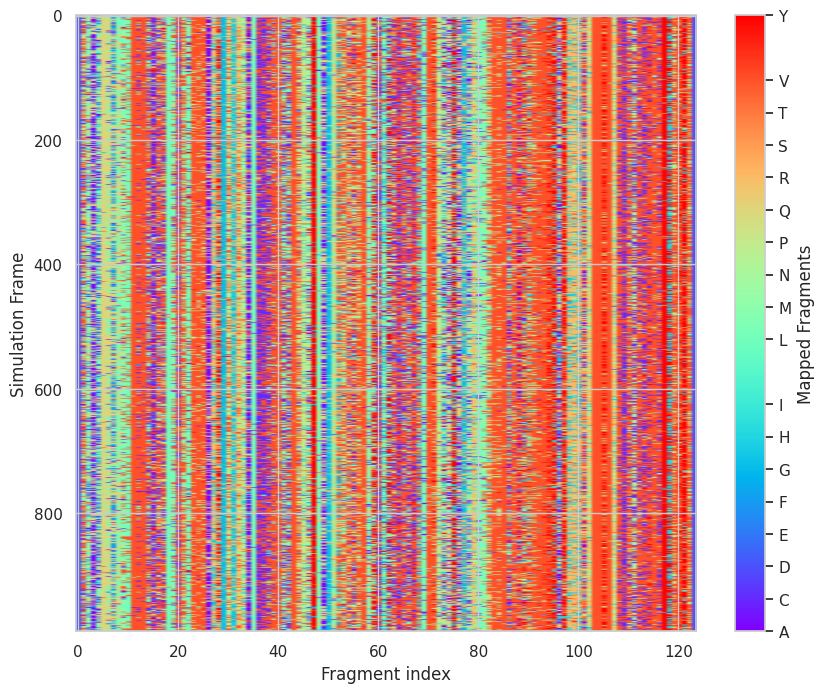

In [28]:
# Plot the randomized trajectory of the Structural Alphabet 3DI of NtrC inactive repl1
Allohub_plots.plot_SA_traj(sa_ntrc_inactive_100_1_3di.get_int_traj(), SAtraj.ALPHABETS["3DI"], action="show")

From the trajectory plots alone, one can already appreciate differences.
M32K25 captures clear differences around the fragments at positions ~90 and shows small difference on stable regions, while the 3DI alphabet also shows differences between the conditions in the region ~80-110 (positions ~90 and ~103).

## Mutual information analysis

Now we will proceed to compute the mutual information for each block.
Each trajectory will produce 9 blocks of 100ns each

In [29]:
print("Calculate the MI information")
# One can specify the number of workers to parallelize the process. max_workers=None would use all available resources.

mi_ntrc_inactive_100_1 = sa_ntrc_inactive_100_1.compute_mis(max_workers=7)
print("NtrC inactive repl 1 finished")
mi_ntrc_inactive_100_2 = sa_ntrc_inactive_100_2.compute_mis(max_workers=7)
print("NtrC inactive repl 2 finished")
mi_ntrc_inactive_100_3 = sa_ntrc_inactive_100_3.compute_mis(max_workers=7)
print("NtrC inactive repl 3 finished")

mi_ntrc_active_100_1 = sa_ntrc_active_100_1.compute_mis(max_workers=7)
print("NtrC active repl 1 finished")
mi_ntrc_active_100_2 = sa_ntrc_active_100_2.compute_mis(max_workers=7)
print("NtrC active repl 2 finished")
mi_ntrc_active_100_3 = sa_ntrc_active_100_3.compute_mis(max_workers=7)
print("NtrC active repl 3 finished")

mi_ntrc_inactive_100_1_3di = sa_ntrc_inactive_100_1_3di.compute_mis(max_workers=7)
print("NtrC inactive, 3di alphabet, repl 1 finished")
mi_ntrc_inactive_100_2_3di = sa_ntrc_inactive_100_2_3di.compute_mis(max_workers=7)
print("NtrC inactive, 3di alphabet, repl 2 finished")
mi_ntrc_inactive_100_3_3di = sa_ntrc_inactive_100_3_3di.compute_mis(max_workers=7)
print("NtrC inactive, 3di alphabet, repl 3 finished")

mi_ntrc_active_100_1_3di = sa_ntrc_active_100_1_3di.compute_mis(max_workers=7)
print("NtrC active, 3di alphabet, repl 1 finished")
mi_ntrc_active_100_2_3di = sa_ntrc_active_100_2_3di.compute_mis(max_workers=7)
print("NtrC active, 3di alphabet, repl 2 finished")
mi_ntrc_active_100_3_3di = sa_ntrc_active_100_3_3di.compute_mis(max_workers=7)
print("NtrC active, 3di alphabet, repl 3 finished")

Calculate the MI information
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:19<00:00,  2.13s/block]


TRAJECTORY COMPLETED
NtrC inactive repl 1 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:20<00:00,  2.25s/block]


TRAJECTORY COMPLETED
NtrC inactive repl 2 finished
ENCODING TRAJECTORY


...

TRAJECTORY COMPLETED
NtrC active, 3di alphabet, repl 1 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:19<00:00,  2.22s/block]


TRAJECTORY COMPLETED
NtrC active, 3di alphabet, repl 2 finished
ENCODING TRAJECTORY


Computing MI: 100%|██████████| 9/9 [00:16<00:00,  1.80s/block]

TRAJECTORY COMPLETED
NtrC active, 3di alphabet, repl 3 finished


## Shanon entropy analysis

Shanon entropy of the fragments gives an idea of sturctural flexibility.
In the case of the M32k25 alphabet this analysis is complementary to cartesian analysis such as RMSF since fragment entropy captures local changes regardless of magnitude of difference thanks to the alphabets being based on internal coordinates.

In [30]:
# Compute the shanon entropy
print("Compute the shanon entropy")

entropy_ntrc_active_1 = sa_ntrc_active_100_1.compute_entropy()
entropy_ntrc_active_2 = sa_ntrc_active_100_2.compute_entropy()
entropy_ntrc_active_3 = sa_ntrc_active_100_3.compute_entropy()

entropy_ntrc_inactive_1 = sa_ntrc_inactive_100_1.compute_entropy()
entropy_ntrc_inactive_2 = sa_ntrc_inactive_100_2.compute_entropy()
entropy_ntrc_inactive_3 = sa_ntrc_inactive_100_3.compute_entropy()

entropy_ntrc_active_1_3di = sa_ntrc_active_100_1_3di.compute_entropy()
entropy_ntrc_active_2_3di = sa_ntrc_active_100_2_3di.compute_entropy()
entropy_ntrc_active_3_3di = sa_ntrc_active_100_3_3di.compute_entropy()

entropy_ntrc_inactive_1_3di = sa_ntrc_inactive_100_1_3di.compute_entropy()
entropy_ntrc_inactive_2_3di = sa_ntrc_inactive_100_2_3di.compute_entropy()
entropy_ntrc_inactive_3_3di = sa_ntrc_inactive_100_3_3di.compute_entropy()

Compute the shanon entropy


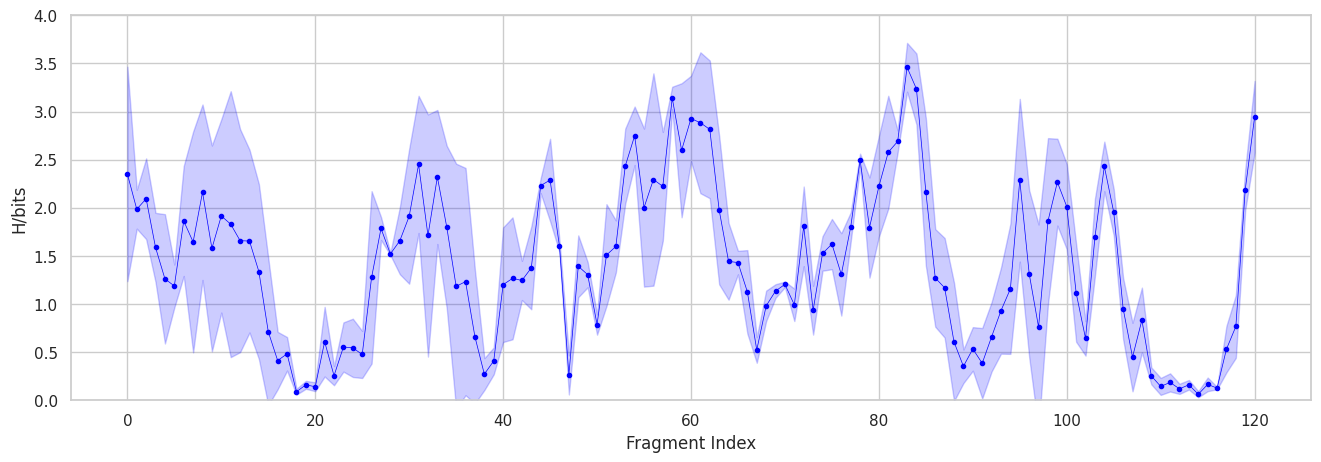

In [31]:
# Plot the entropies of active NtrC with their standard deviations for the trajectories encoded with M32k25 alphabet.
Allohub_plots.plot_shannon_entropy_sd([entropy_ntrc_active_1, entropy_ntrc_active_2, entropy_ntrc_active_3], action="show", ylim=(0,4))

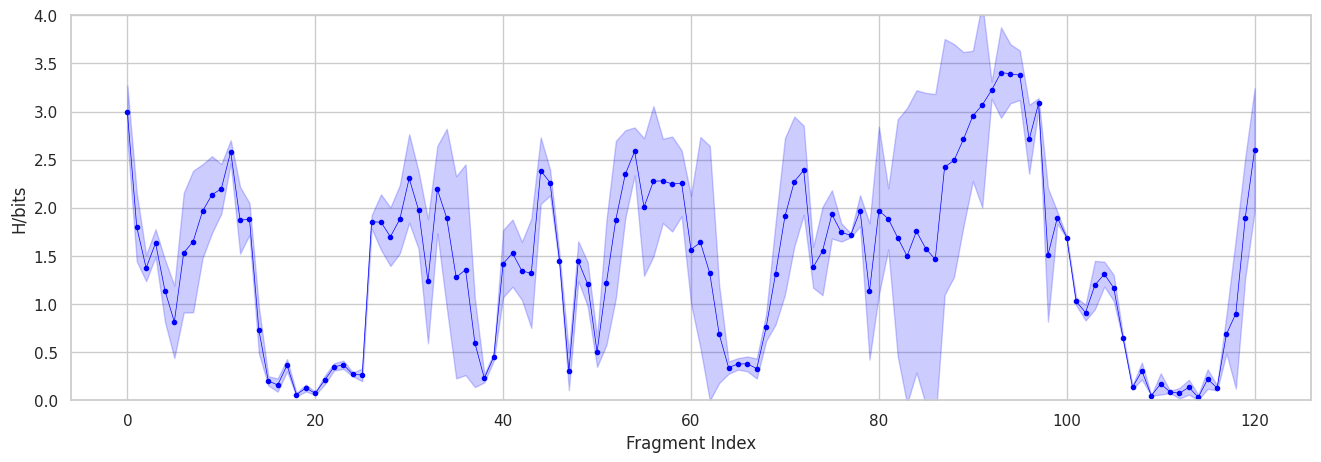

In [32]:
# Plot the entropies of inactive NtrC with their standard deviations for the trajectories encoded with M32k25 alphabet.
Allohub_plots.plot_shannon_entropy_sd([entropy_ntrc_inactive_1, entropy_ntrc_inactive_2, entropy_ntrc_inactive_3], action="show", ylim=(0,4))

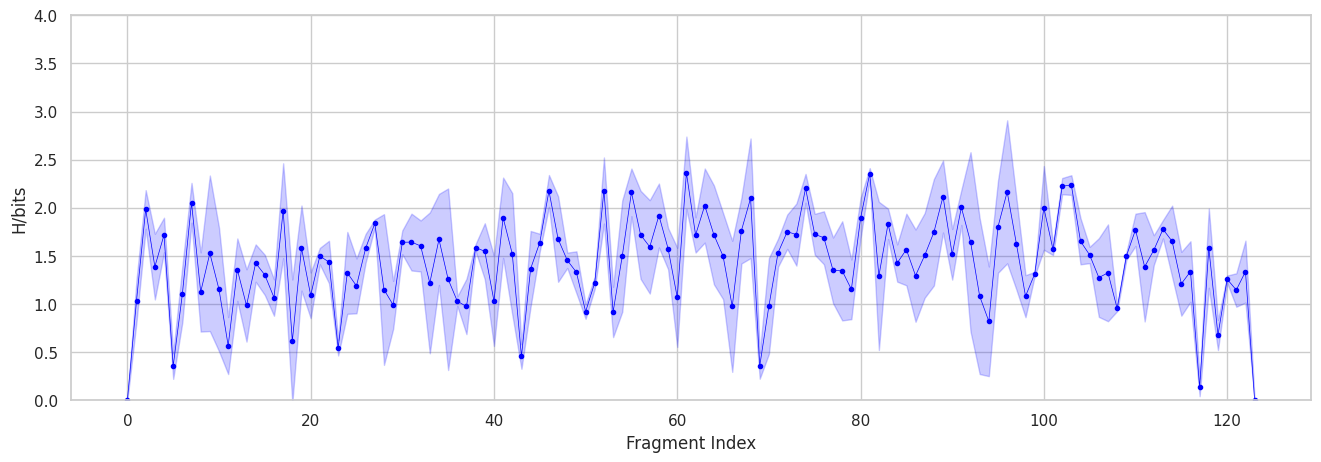

In [33]:
# Plot the entropies of active NtrC with their standard deviations for the trajectories encoded with 3di alphabet.
Allohub_plots.plot_shannon_entropy_sd([entropy_ntrc_active_1_3di, entropy_ntrc_active_2_3di, entropy_ntrc_active_3_3di], action="show", ylim=(0,4))

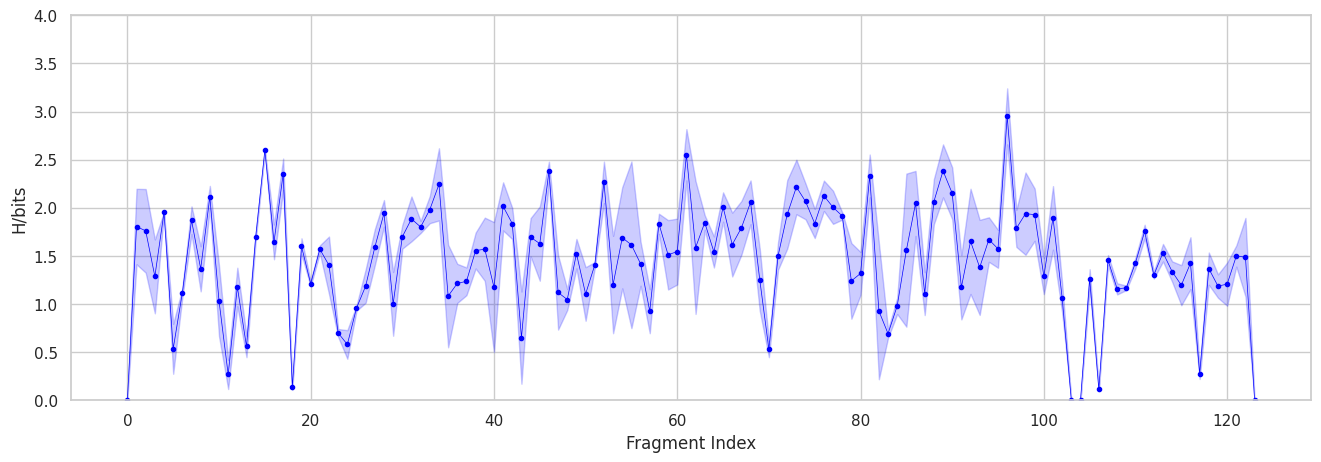

In [34]:
# Plot the entropies of inactive NtrC with their standard deviations for the trajectories encoded with 3di alphabet.
Allohub_plots.plot_shannon_entropy_sd([entropy_ntrc_inactive_1_3di, entropy_ntrc_inactive_2_3di, entropy_ntrc_inactive_3_3di], action="show", ylim=(0,4))

The differences can be better observed by substracting the mean entropy arrays.

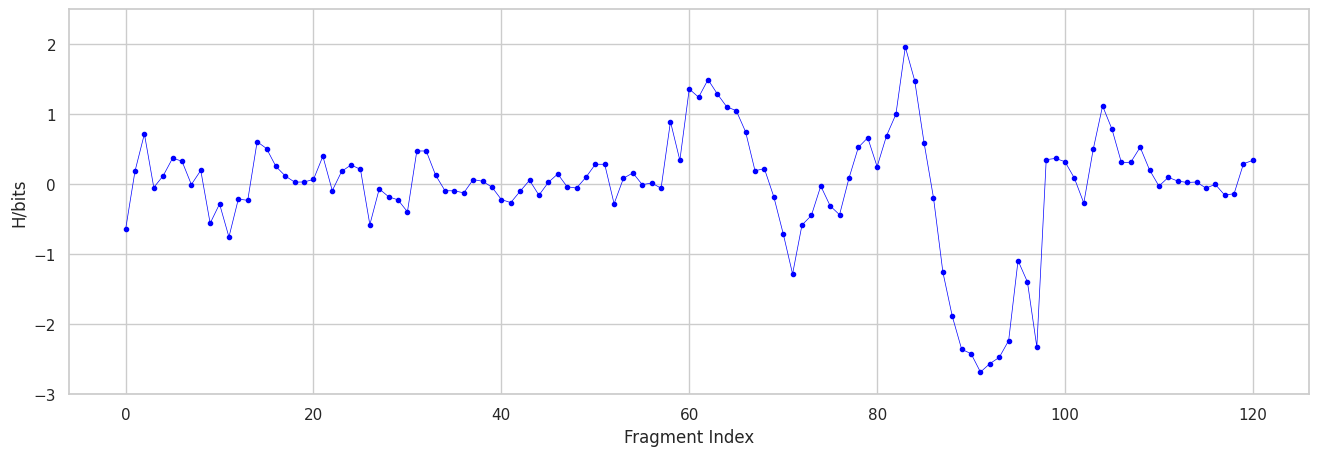

In [35]:
# Compute the mean entropy per condition for the M32K25 alphabet
mean_act = np.mean([np.array(entropy_ntrc_active_1), np.array(entropy_ntrc_active_2), np.array(entropy_ntrc_active_3)], axis=0)

mean_inact = np.mean([np.array(entropy_ntrc_inactive_1), np.array(entropy_ntrc_inactive_2), np.array(entropy_ntrc_inactive_3)], axis=0)

diff = mean_act - mean_inact
# Plot the mean entropy
Allohub_plots.plot_shannon_entropy(diff, ylim=(-3,2.5), action="show", name="mk_entro.svg")

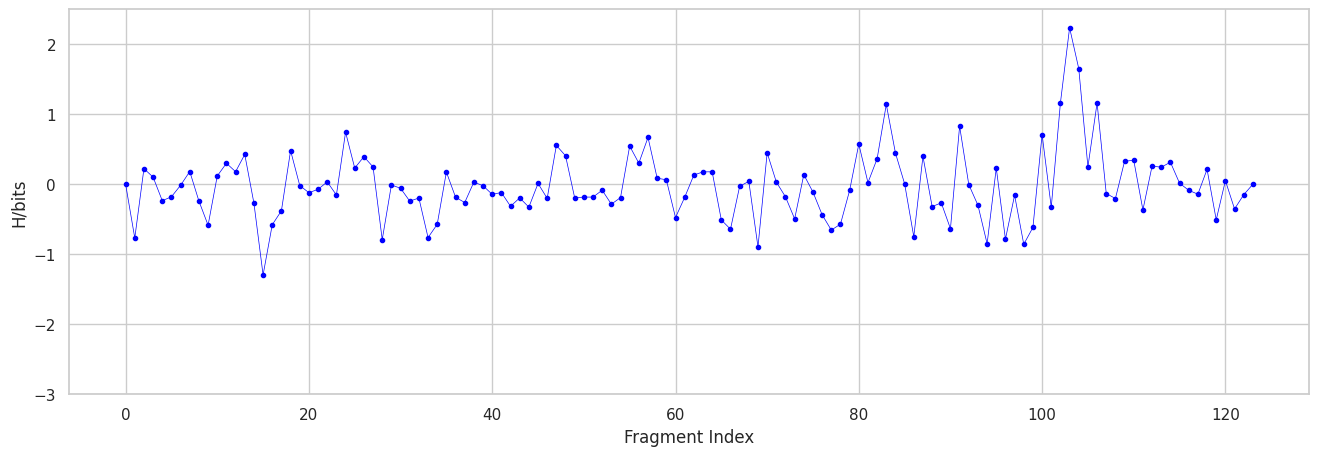

In [36]:
# Compute the mean entropy per condition for the 3di alphabet
mean_act = np.mean([np.array(entropy_ntrc_active_1_3di), np.array(entropy_ntrc_active_2_3di), np.array(entropy_ntrc_active_3_3di)], axis=0)

mean_inact = np.mean([np.array(entropy_ntrc_inactive_1_3di), np.array(entropy_ntrc_inactive_2_3di), np.array(entropy_ntrc_inactive_3_3di)], axis=0)

diff = mean_act - mean_inact
# Plot the mean entropy
Allohub_plots.plot_shannon_entropy(diff, ylim=(-3,2.5), action="show", name="entro_3di.svg")

Positions around fragment 60 and 90 are known positions that undergo conformational and flexibility changes, suggesting that the approach correctly described this effect.
The M32K25 alphabet shows both regions clearly. The 3DI alphabet shows its largest entropy change around position ~103, a decrease around ~91-99 and only a weak signal around 60.

# Analysis of allosteric Signal

Following the previous analysis, we will now extract important fragments and possible signaling path for the NtrC.
For that we will use the trajectories encoded with M32K25, which managed to capture the conformation space changes with more sensitivity.

## Eigenvector decomposition

The eigenvector decomposition of the obtained MI matrices can be used to asses convergence.
The main motions of well converged simulations should have relatively high eigenvector overlap (>0.3).

Overlap between replicates can be used as a way to asses relaiability of the results. (Higher convergences = Higher confidences).

In [37]:
# Do an eigenvector decomposition of the matrices
from tqdm import tqdm

print("Do an eigenvector decomposition of the matrices")

for mi_tr in tqdm(mi_ntrc_active_100_1, desc="Eigenvector decomposition for NtrC active 1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_2, desc="Eigenvector decomposition for NtrC active 2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_active_100_3, desc="Eigenvector decomposition for NtrC active 3", unit="matrix"):
    mi_tr.compute_eigensystem()

for mi_tr in tqdm(mi_ntrc_inactive_100_1, desc="Eigenvector decomposition for NtrC inactive 1", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_2, desc="Eigenvector decomposition for NtrC inactive 2", unit="matrix"):
    mi_tr.compute_eigensystem()
for mi_tr in tqdm(mi_ntrc_inactive_100_3, desc="Eigenvector decomposition for NtrC inactive 3", unit="matrix"):
    mi_tr.compute_eigensystem()

Do an eigenvector decomposition of the matrices


Eigenvector decomposition for NtrC inactive 3: 100%|██████████| 9/9 [00:00<00:00, 140.35matrix/s]


## Convergence analysis

Overlap can be now computed using the Overlap object.

In this analysis we are using the top 3 eigenvectors which should explain most of the observed variability.

In [38]:
# Create the overlap handler to compute similarities between the trajectories

# M32K25
overlap_100 = Overlap.Overlap([mi_ntrc_inactive_100_1, mi_ntrc_inactive_100_2, mi_ntrc_inactive_100_3,
                               mi_ntrc_active_100_1,  mi_ntrc_active_100_2, mi_ntrc_active_100_3], ev_list=[0,1,2])
overlap_100.fill_overlap_matrix()

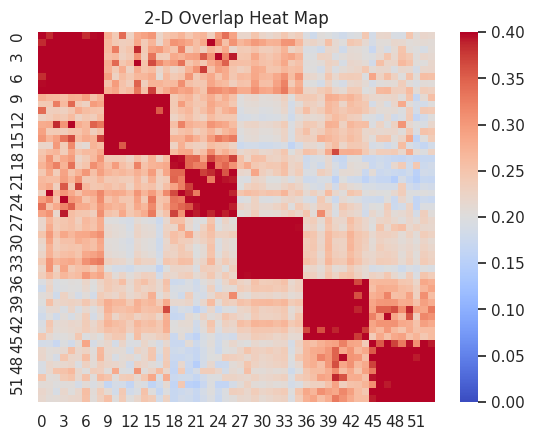

In [39]:
# Convergence with alphabet M32K25
Allohub_plots.plot_overlap(overlap_100.get_overlap_matrix(), vmax=0.4, action="show")

In [40]:
# Compute similarities between overlap matrices
similarity_matrix_100 = overlap_100.compute_similarities()

SIMILARITIES BETWEEN TRAJECTORY 0  and 1
	Overlap between trajectories: 0.2707
	Overlap of trajectory 1 with itself: 0.5124
	Overlap of trajectory 2 with itself: 0.552
 Similary 0.7385
SIMILARITIES BETWEEN TRAJECTORY 0  and 2
	Overlap between trajectories: 0.2833
	Overlap of trajectory 1 with itself: 0.5124
	Overlap of trajectory 2 with itself: 0.4563
 Similary 0.7989
SIMILARITIES BETWEEN TRAJECTORY 0  and 3
	Overlap between trajectories: 0.264
	Overlap of trajectory 1 with itself: 0.5124
	Overlap of trajectory 2 with itself: 0.5562
 Similary 0.7297
SIMILARITIES BETWEEN TRAJECTORY 0  and 4
	Overlap between trajectories: 0.2122
	Overlap of trajectory 1 with itself: 0.5124
	Overlap of trajectory 2 with itself: 0.5315
 Similary 0.6903
SIMILARITIES BETWEEN TRAJECTORY 0  and 5
	Overlap between trajectories: 0.2185
	Overlap of trajectory 1 with itself: 0.5124
	Overlap of trajectory 2 with itself: 0.5191
 Similary 0.7027
SIMILARITIES BETWEEN TRAJECTORY 1  and 2
	Overlap between trajectories: 

In [41]:
# Statistic significance of convergence for M32K25
# The groups are simulation 0,1,2 inactive 3,4,5 active
# The similarity_matrix contains the overlap between the indexed trajectories.
within_conditions = [similarity_matrix_100[0][1], similarity_matrix_100[0][2], similarity_matrix_100[1][2], 
                     similarity_matrix_100[3][4], similarity_matrix_100[3][5], similarity_matrix_100[4][5]]

between_conditions = [similarity_matrix_100[0][3], similarity_matrix_100[0][4], similarity_matrix_100[0][5], 
                      similarity_matrix_100[1][3], similarity_matrix_100[1][4], similarity_matrix_100[1][5],
                      similarity_matrix_100[2][3], similarity_matrix_100[2][4], similarity_matrix_100[2][5]]

tat, p_value = ttest_ind(within_conditions, between_conditions, equal_var=False, alternative='greater')

print(f"p-value of convergence within vs between conditions for NtrC with alphabet M32K25 is {p_value}")

p-value of convergence within vs between conditions for NtrC with alphabet M32K25 is 0.007290212688868098


The obtained p-value indicates that the convergence within replicates is signicantly different than the convergence between conditions, meaning that the analysis captured unique signal for this system.

## Up and down regulated fragments detection

The next step is to find up and down regulated fragments.
For that, one needs the mapping of trajectories, that is to which condition each simulation belongs. 

In this case we have two conditions, inactive (0) and active (1).

The argument splitting controls wether the statistics should be compute using the mean mi matrices per replicate (splitting = False) or using all the mi matrices (splitting = True).

Using all mi matrices will show more coupled fragments but will produce a higher degree of false positives.

For this analysis we will use all mi matrices.

In [42]:
# Find upregulated and downregulated fragments
print("Find upregulated and downregulated fragments")

# The fold change of non correlated points would produce a division by zero runtime warning this warnings can be silenced as following:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

updown_regulated_fragments = overlap_100.updown_regulation(traj_mapping=[0,0,0,1,1,1],splitting=True)

# The obtained dictionary has as keys the pairs of conditions. In this case (0,1).
# If more conditions were used one would have all the additional pairing (0,1), (0,2), (1,2) ....
t12_updown = updown_regulated_fragments[(0,1)]

Find upregulated and downregulated fragments
     FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
0           (0, 1)       -0.123072  0.447505  0.203693  0.221832   
1           (0, 2)       -0.892619  0.000013  0.099332  0.184413   
2           (0, 3)       -0.184633  0.177322  0.069483  0.078970   
3           (0, 4)       -0.329466  0.059657  0.053082  0.066700   
4           (0, 5)       -0.466802  0.039576  0.043965  0.060762   
...            ...             ...       ...       ...       ...   
7255    (117, 119)        0.373160  0.304201  0.062857  0.048531   
7256    (117, 120)        0.312794  0.305761  0.051024  0.041078   
7257    (118, 119)        1.172576  0.025107  0.189950  0.084267   
7258    (118, 120)        1.031750  0.027216  0.115946  0.056711   
7259    (119, 120)       -0.338872  0.035184  0.178182  0.225359   

      AdjustedPValues  
0            0.564435  
1            0.000086  
2            0.284247  
3            0.120109  
4            0.085

Now we can filter the up and down regulated fragments based on a p value and fold change

In [43]:
# Filtering parameters
pval_threshold = 0.01
fold_change_threshold = 2

# First extract individual fragments for ease of access
fragment_pairs = t12_updown["FragmentPairs"]
f1 = [x[0] for x in fragment_pairs]
f2 = [x[1] for x in fragment_pairs]
t12_updown["f1"] = f1
t12_updown["f2"] = f2

# Now extract significant fragments
significant_fragments = t12_updown[t12_updown['AdjustedPValues'] < pval_threshold]

# Second, filter by fold change and print top 10
up_reg = significant_fragments[significant_fragments['log2FoldChange'] > fold_change_threshold].sort_values('log2FoldChange', ascending=False)
up_reg.head(10)

,FragmentPairs,log2FoldChange,PValues,MIfrag1,MIfrag2,AdjustedPValues,f1,f2
1776,"(15, 97)",8.532368,1.185237e-09,0.018100,0.000049,2.167462e-08,15,97
2865,"(26, 97)",6.128607,3.101384e-18,0.067268,0.000961,8.595436e-16,26,97
1131,"(9, 97)",4.491642,5.392162e-12,0.098169,0.004364,1.747638e-10,9,97
6801,"(90, 97)",4.491203,4.398142e-11,0.198793,0.008839,1.178248e-09,90,97
1020,"(8, 97)",3.955166,3.650898e-08,0.100521,0.006481,4.699560e-07,8,97
6798,"(90, 94)",3.853023,1.419360e-12,0.213251,0.014758,5.339146e-11,90,94
6771,"(89, 97)",3.794233,5.331726e-18,0.148517,0.010705,1.315670e-15,89,97
6734,"(88, 91)",3.791199,2.299070e-15,0.218899,0.015812,2.035518e-13,88,91
6702,"(87, 91)",3.700160,6.531406e-09,0.189802,0.014603,1.013205e-07,87,91
3666,"(35, 97)",3.661259,3.868767e-05,0.078112,0.006174,2.319343e-04,35,97


In [44]:
# Show top 10 Down-regulated fragments
down_reg = significant_fragments[significant_fragments['log2FoldChange'] < -fold_change_threshold].sort_values('log2FoldChange')
down_reg.head(10)


,FragmentPairs,log2FoldChange,PValues,MIfrag1,MIfrag2,AdjustedPValues,f1,f2
7000,"(97, 114)",-7.217936,5.620106e-04,0.002506,0.373074,2.370829e-03,97,114
6998,"(97, 112)",-5.587055,2.927741e-03,0.006223,0.299114,9.810783e-03,97,112
1705,"(15, 26)",-4.293820,1.711025e-03,0.016287,0.319453,6.220353e-03,15,26
5608,"(63, 65)",-3.919232,2.708481e-06,0.011904,0.180095,2.254997e-05,63,65
693,"(5, 109)",-3.784171,4.903936e-06,0.001002,0.013803,3.770718e-05,5,109
2592,"(23, 109)",-3.655443,6.461892e-04,0.000787,0.009920,2.668811e-03,23,109
299,"(2, 63)",-3.611394,4.581427e-14,0.012962,0.158417,2.618989e-12,2,63
5643,"(63, 100)",-3.494594,3.211577e-06,0.018371,0.207065,2.596442e-05,63,100
5492,"(61, 64)",-3.277393,1.884261e-07,0.020929,0.202931,2.075832e-06,61,64
5702,"(64, 103)",-3.276246,7.115188e-07,0.007775,0.075331,6.726076e-06,64,103


In [45]:
# Most frequent fragments
top_fragments_count = {}

for fragment_pair in up_reg["FragmentPairs"]:
    top_fragments_count.setdefault(fragment_pair[0], 0) # record first fragment of the pair
    top_fragments_count.setdefault(fragment_pair[1], 0) # record second fragment of the pair
    top_fragments_count[fragment_pair[0]] += 1
    top_fragments_count[fragment_pair[1]] += 1

for fragment_pair in down_reg["FragmentPairs"]:
    top_fragments_count.setdefault(fragment_pair[0], 0) # record first fragment of the pair
    top_fragments_count.setdefault(fragment_pair[1], 0) # record second fragment of the pair
    top_fragments_count[fragment_pair[0]] += 1
    top_fragments_count[fragment_pair[1]] += 1

# sort based on counts
top_fragments_count = dict(sorted(top_fragments_count.items(), key=lambda item: item[1], reverse=True))

# Print top 10 most appearing fragments
dict_keys = list(top_fragments_count.keys())
for i in range(10):
    frag = dict_keys[i]
    print(f"Fragment {frag} appears {top_fragments_count[frag]} times.")


Fragment 89 appears 58 times.
Fragment 64 appears 56 times.
Fragment 90 appears 55 times.
Fragment 91 appears 55 times.
Fragment 63 appears 54 times.
Fragment 109 appears 52 times.
Fragment 97 appears 41 times.
Fragment 92 appears 31 times.
Fragment 88 appears 20 times.
Fragment 65 appears 14 times.


Interpretation

One can also create a volcano plot of the data to visualize the results

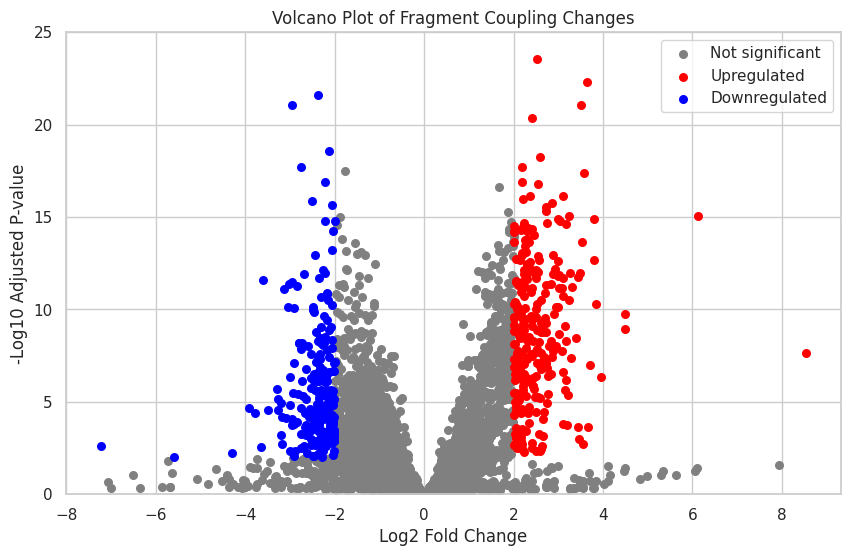

In [46]:
# Plot volcano plot of Up and Down regulated fragments
Allohub_plots.plot_updownregulation(t12_updown,  fold_threshold=fold_change_threshold, ylim=25, pvalue_threshold=pval_threshold, action="show")

In [47]:
# Check the pair 82 - 101
sorted_significant_fragments = significant_fragments.sort_values(by="log2FoldChange", key=abs, ascending=False).reset_index(drop=False)

print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (80,99)]) # Fragments that contain residue 82 would be 79-82
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (81,99)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (82,99)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (80,100)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (81,100)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (82,100)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (80,101)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (81,101)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (82,101)])

Empty DataFrame
Columns: [index, FragmentPairs, log2FoldChange, PValues, MIfrag1, MIfrag2, AdjustedPValues, f1, f2]
Index: []
      index FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
1907   6497      (81, 99)       -0.799061  0.000201  0.073269  0.127486   

      AdjustedPValues  f1  f2  
1907         0.000986  81  99  
      index FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
2023   6535      (82, 99)       -0.694237  0.000503  0.070213  0.113607   

      AdjustedPValues  f1  f2  
2023         0.002148  82  99  
      index FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
2087   6459     (80, 100)       -0.629192  0.000991  0.060742  0.093949   

      AdjustedPValues  f1   f2  
2087         0.003858  80  100  
      index FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
1778   6498     (81, 100)       -0.899205  0.000035  0.069115  0.128903   

      AdjustedPValues  f1   f2  
1778          0.00021  81  100  
      inde

In [48]:
# Check the pair 66 - 99
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (64,97)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,97)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,97)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (64,98)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,98)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,98)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (64,99)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,99)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,99)])

# check  67 - (95,96)
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,94)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,94)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (67,94)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,95)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,95)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (67,95)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (65,96)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (66,96)])
print(sorted_significant_fragments[sorted_significant_fragments["FragmentPairs"] == (67,96)])

Empty DataFrame
Columns: [index, FragmentPairs, log2FoldChange, PValues, MIfrag1, MIfrag2, AdjustedPValues, f1, f2]
Index: []
Empty DataFrame
Columns: [index, FragmentPairs, log2FoldChange, PValues, MIfrag1, MIfrag2, AdjustedPValues, f1, f2]
Index: []
Empty DataFrame
Columns: [index, FragmentPairs, log2FoldChange, PValues, MIfrag1, MIfrag2, AdjustedPValues, f1, f2]
Index: []
     index FragmentPairs  log2FoldChange       PValues   MIfrag1   MIfrag2  \
730   5697      (64, 98)       -1.707584  6.775741e-07  0.023001  0.075124   

     AdjustedPValues  f1  f2  
730         0.000006  64  98  
     index FragmentPairs  log2FoldChange  PValues   MIfrag1   MIfrag2  \
868   5752      (65, 98)       -1.571165  0.00001  0.020251  0.060174   

     AdjustedPValues  f1  f2  
868         0.000073  65  98  
      index FragmentPairs  log2FoldChange   PValues   MIfrag1   MIfrag2  \
1181   5806      (66, 98)       -1.307703  0.000834  0.026758  0.066238   

      AdjustedPValues  f1  f2  
1181       

Due to the 4 aminoaciod size nautre of the fragments, important fragments have to be seen as hubs of key residues rather than plain positions. To try to Disambiguate the aminoa acids with higher weight in the top fragments we will use Protein Language Models in the next section. 

From the top differentialy regulated fragments we find positions with key reported residues involved in the activation of the protein.
The previously reported Y101 - T82 switch appears in the significant hits as well as other important reported structural differences such as position ~99 and ~94 with the key structural switches of residues F99 and Y94 respectively. Interestingly, F99 and Y94 appear more consistently highlighting their higher importance as a activation characteristic.

On the top fragment pairs hits we find previously reported relevant structural contacts, such as the K(67) - Q(96) - Q(95) (KQQ motif) and the F99-L66 pair.
Other residues from the β3−α3 loop(residue indices 60−63) and from the N-terminal half of α4 (residues indices 85−90)also appear among the most important parts, matching with the NMR experiments performed for this system.

## Disambiguation of Fragments

To find which might be the most important residues for a given fragment, one can use PLM such as ESM2-650M and use the predicted likelihoods as a guide.
The next section will ilustrate how to do that.
First the distances between c alphas need to be calculated, after that the important residues can be extracted with the SAPLM module.

In [49]:
# Compute distances between c alphas from a pdb
import mdtraj as md

# Load trajectory
traj = md.load("data_NtrC/NtrC_active_nowat.pdb")

# Select only the C-alpha atoms
ca_indices = traj.topology.select('name CA')


# Extract the coordinates of C-alpha atoms
ca_positions = traj.xyz[0][ca_indices]

# Number of points
n_points = ca_positions.shape[0]

# Initialize an empty distance matrix
distance_matrix = np.zeros((n_points, n_points))

# Compute the pairwise distances using loops
for i in range(n_points):
    for j in range(n_points):
        # Compute Euclidean distance between points i and j
        distance_matrix[i, j] = np.sqrt(np.sum((ca_positions[i] - ca_positions[j])**2))

# Convert to angstroms
distance_matrix *= 10

In [50]:
from Allohubpy import SAPLM
# The sequence should match the one used in the simulations
traj = md.load("data_NtrC/NtrC_active_nowat.pdb")

# Create a subset trajectory containing only the protein
protein_traj = traj.atom_slice(traj.topology.select("protein"))

ntrc_sequence = ''.join([str(residue.code) for residue in protein_traj.topology.residues])


# Create the PLM handler. The fragment size for alphabet M32k25 is 4
esm_handler = SAPLM.SAPLM(fragment_size = 4)
esm_handler.set_sequence(ntrc_sequence)

# Extract likelihoods for top most appearing fragments
likelihood_df = esm_handler.fragment_likelihoods(fragment=64, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=63, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=90, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=91, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=89, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=109, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=97, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=92, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=88, offset=0)
print(likelihood_df)

likelihood_df = esm_handler.fragment_likelihoods(fragment=93, offset=0)
print(likelihood_df)

   Amino acid position Amino acid  Likelihood
0                   65          L    0.997173
1                   66          L    0.994718
2                   67          K    0.739040
3                   68          Q    0.889384
   Amino acid position Amino acid  Likelihood
0                   64          A    0.887619
1                   65          L    0.997173
2                   66          L    0.994718
3                   67          K    0.739040
   Amino acid position Amino acid  Likelihood
0                   91          V    0.699972
1                   92          S    0.796207
2                   93          A    0.990187
3                   94          Y    0.023101
   Amino acid position Amino acid  Likelihood
0                   92          S    0.796207
1                   93          A    0.990187
2                   94          Y    0.023101
3                   95          Q    0.803866
   Amino acid position Amino acid  Likelihood
0                   90          A 

##Graph Analysis

Finally, we can examine possible comuniaction path between the phosphorilation site D54 which induces the shift to the active conformation of NtrC to positions found in the signaling surface that were picked up as significant in the previous steps (88-100).

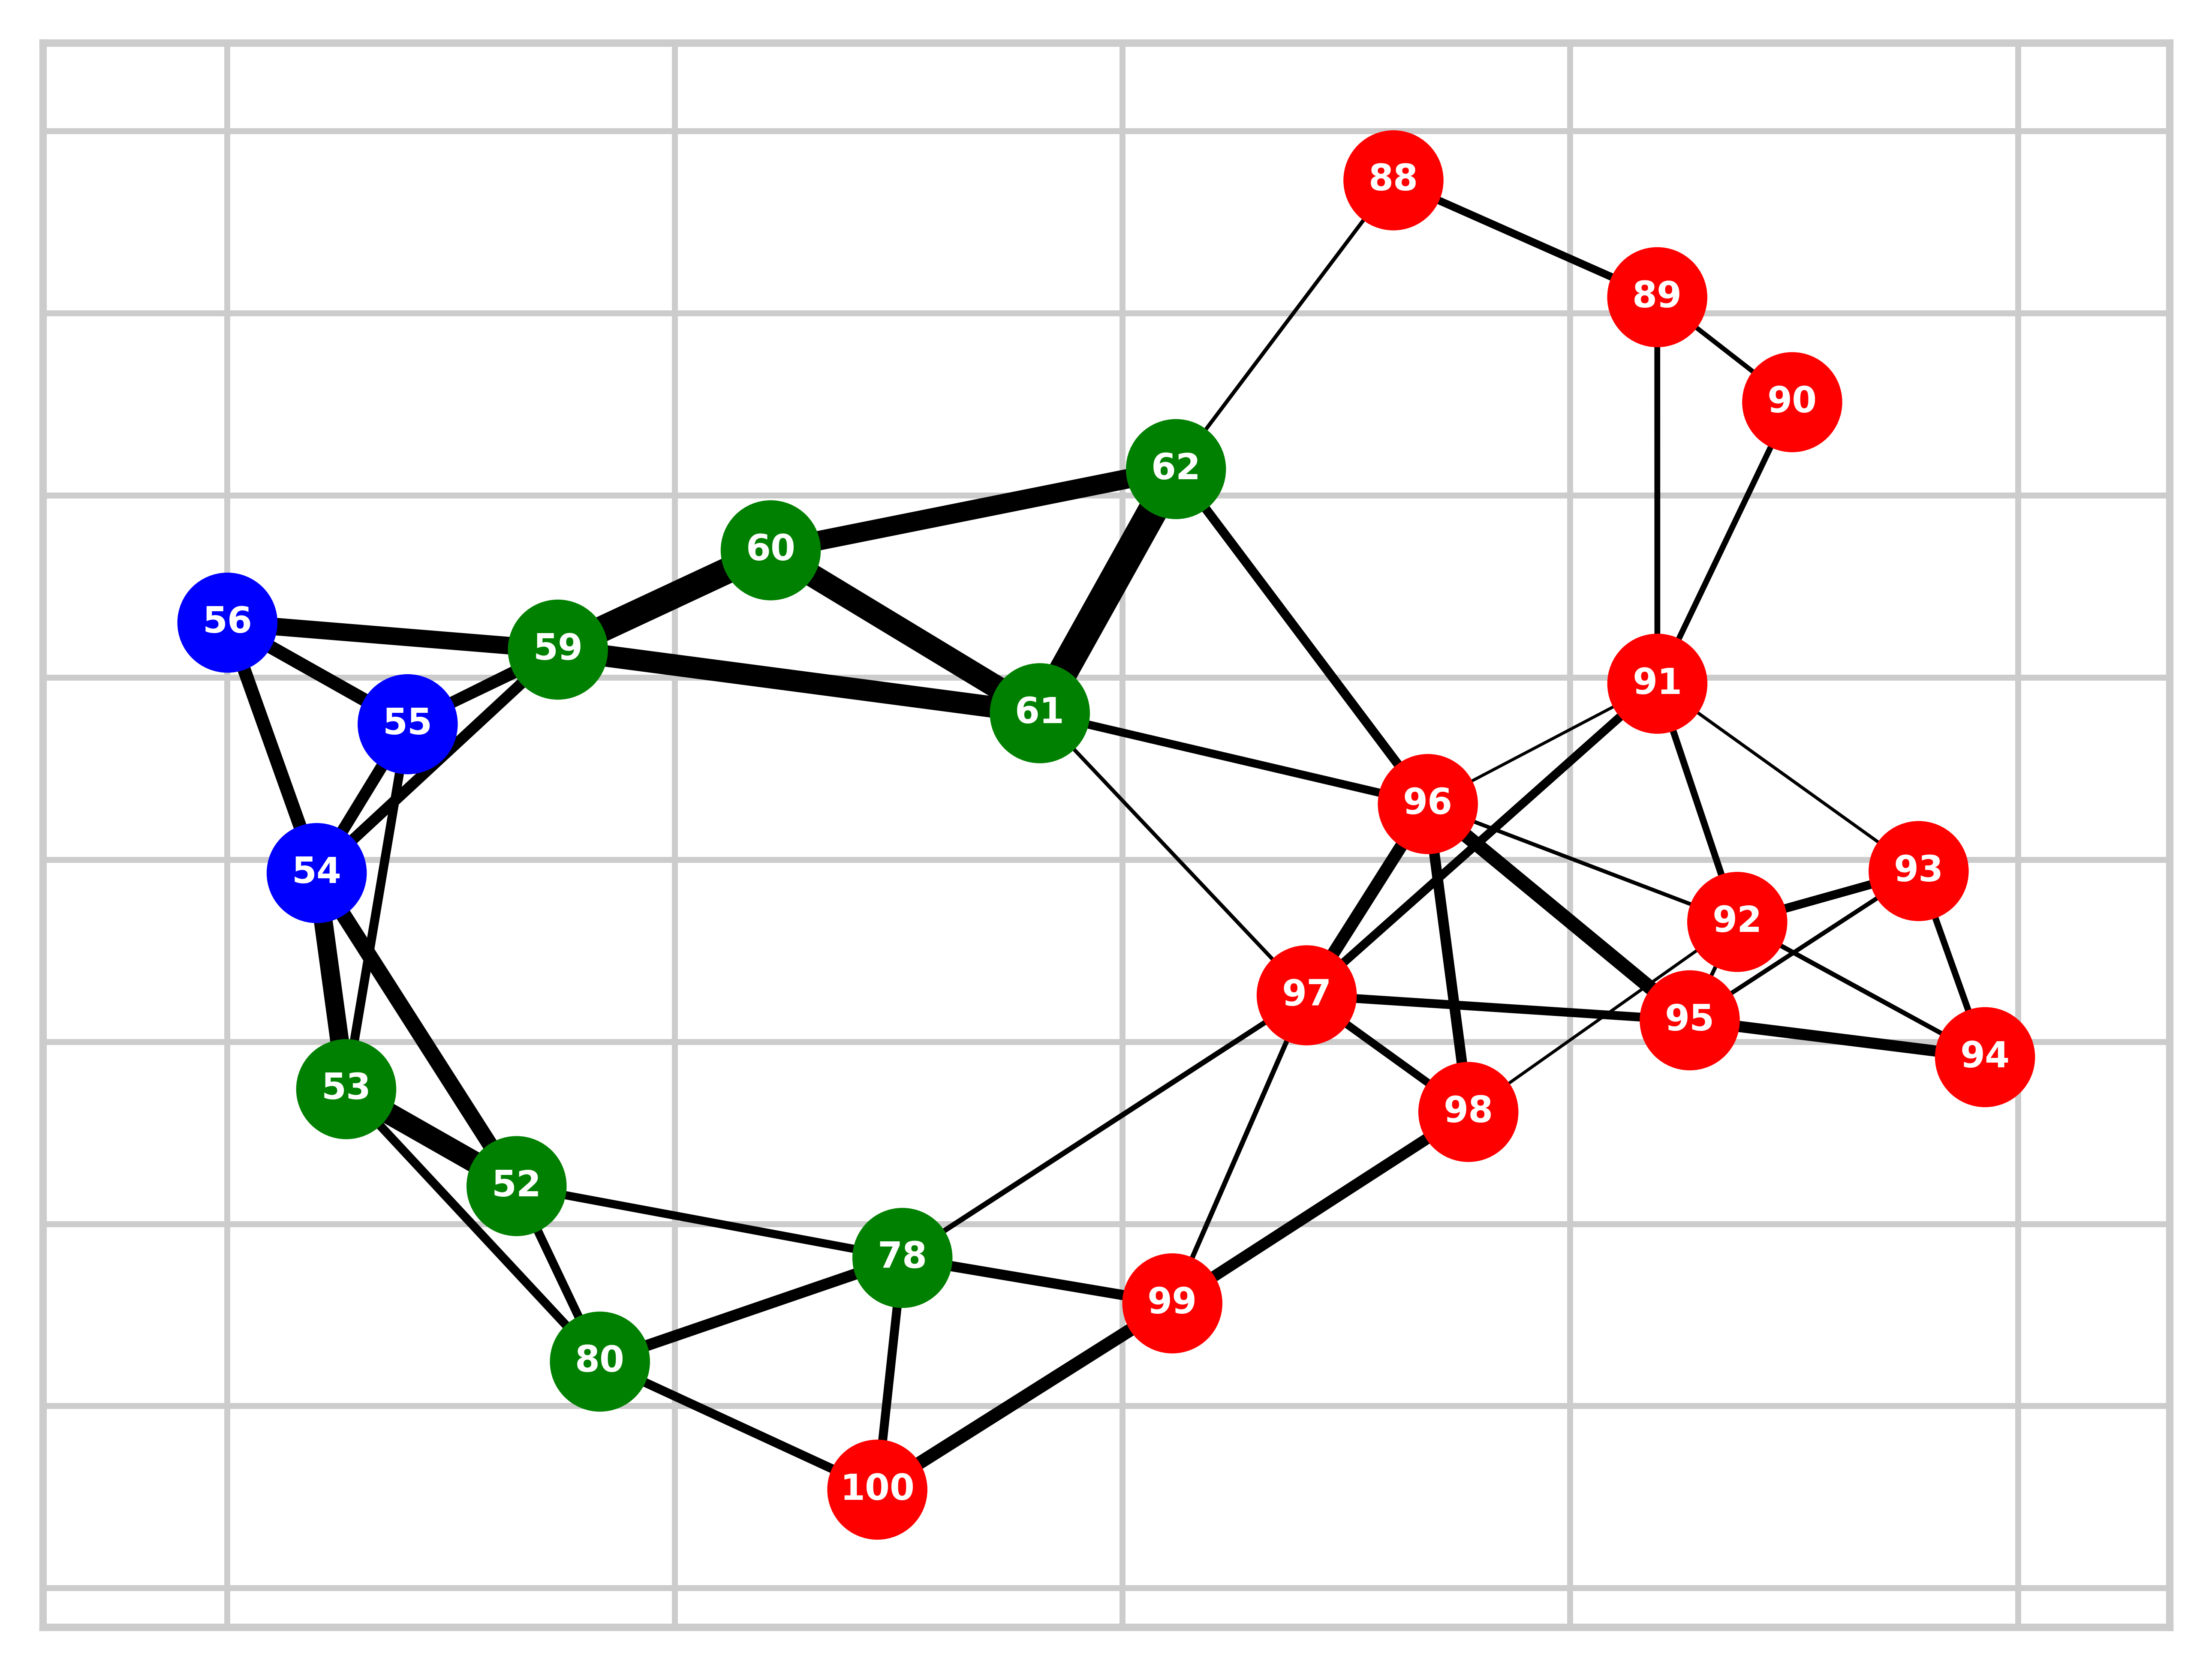

In [51]:
import importlib
importlib.reload(SANetwork)
# We are interested in the signal transmition from D54
SAgraph = SANetwork.SANetWork(traj_list= mi_ntrc_active_100_1 + mi_ntrc_active_100_2 + mi_ntrc_active_100_3, distance_limit=7)

# Load the distances. The fragment size for M32k25 is 4.
SAgraph.set_distance_matrix(matrix=distance_matrix, fragment_size=4)

# The pval_threshold filters coupled pairs with low significance
SAgraph.create_graph(threshold=50)

# list of fragments of interest
start = [54,55,56]
end = [i for i in range(88,101)]

# Subgraph is a networkx object with the nodes and edges of the shortest paths connecting those residues
# Shortest_pathd ans shortest_distances are list of the shortest paths and their distances respectively.
# z_score provides an estimate of how statistically coupled the two sites are
subgraph, shortest_paths, shortest_distances, z_score = SAgraph.identify_preferential_connections(start_fragments=start, end_fragments=end)

# Create representation of the graph
Allohub_plots.plot_SA_graph(subgraph, start, end, action="show")